# Estandarización y Análisis de Componentes Principales (PCA)

En este notebook estudiaremos dos herramientas fundamentales para el análisis de datos multivariados:

1. **Estandarización de variables**.
2. **Análisis de Componentes Principales (PCA)**.

Trabajaremos con datos de casos semanales de dengue registrados en las entidades federativas de México.

Cada observación corresponde a una semana y cada variable representa el número de casos registrados en una entidad.

Por tanto, nuestros datos pueden representarse mediante una matriz

$$
X=
\begin{pmatrix}
x_{11} & x_{12} & \cdots & x_{1p}\\
x_{21} & x_{22} & \cdots & x_{2p}\\
\vdots & \vdots & \ddots & \vdots\\
x_{n1} & x_{n2} & \cdots & x_{np}
\end{pmatrix},
$$

donde $x_{ij}$ representa el número de casos de dengue observados en la semana $i$ para la entidad $j$.

En nuestro caso:

- las **filas** representan semanas;
- las **columnas** representan entidades federativas;
- las variables se encuentran en la misma unidad, pero pueden presentar magnitudes y variabilidades muy diferentes.

Antes de aplicar PCA estudiaremos la estructura del conjunto de datos y analizaremos por qué puede ser necesario estandarizar las variables.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
ruta = 'https://raw.githubusercontent.com/jamc88/TSMA-II-26-O/refs/heads/main/Datos/casos_semanales_dengue_2020_2026.csv'
datos = pd.read_csv(ruta,parse_dates=["FECHA"])
datos

,FECHA,AGUASCALIENTES,BAJA CALIFORNIA,BAJA CALIFORNIA SUR,CAMPECHE,CHIAPAS,CHIHUAHUA,COAHUILA,COLIMA,DISTRITO FEDERAL,...,QUINTANA ROO,SAN LUIS POTOSI,SINALOA,SONORA,TABASCO,TAMAULIPAS,TLAXCALA,VERACRUZ,YUCATAN,ZACATECAS
0,2020-01-05,0,1,0,5,2,0,1,2,1,...,24,0,5,0,16,5,0,41,12,0
1,2020-01-12,0,1,1,5,12,1,1,4,2,...,33,0,12,2,21,6,0,69,10,0
2,2020-01-19,0,0,0,2,14,0,0,10,1,...,35,0,3,0,22,3,0,87,19,0
3,2020-01-26,0,0,1,7,8,0,0,2,0,...,28,0,11,1,30,10,0,66,21,0
4,2020-02-02,0,0,0,2,8,0,0,4,0,...,19,1,4,0,26,9,0,58,14,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
329,2026-04-26,0,0,4,1,4,0,0,0,0,...,3,0,11,27,16,3,0,15,0,0
330,2026-05-03,0,0,6,0,9,0,0,0,0,...,4,0,14,38,14,0,0,13,0,0
331,2026-05-10,0,0,8,1,3,0,0,0,1,...,4,1,16,50,8,1,0,7,1,0
332,2026-05-17,0,0,5,0,4,0,0,0,0,...,4,0,13,34,10,0,0,0,0,0


In [3]:
print("Dimensiones del conjunto de datos:")
print(datos.shape)

print("\nPeriodo:")
print(datos["FECHA"].min(),"a",datos["FECHA"].max())

print("\nNúmero de semanas:")
print(len(datos))

print("\nNúmero de entidades:")
print(datos.shape[1] - 1)

print("\nValores faltantes:")
print(datos.isna().sum().sum())

print("\nFechas duplicadas:")
print(datos["FECHA"].duplicated().sum())

# Frecuencia temporal
diferencias = datos["FECHA"].diff().dropna()
print("\nDiferencias entre fechas:")
print(diferencias.value_counts())

Dimensiones del conjunto de datos:
(334, 33)

Periodo:
2020-01-05 00:00:00 a 2026-05-24 00:00:00

Número de semanas:
334

Número de entidades:
32

Valores faltantes:
0

Fechas duplicadas:
0

Diferencias entre fechas:
FECHA
7 days    333
Name: count, dtype: int64


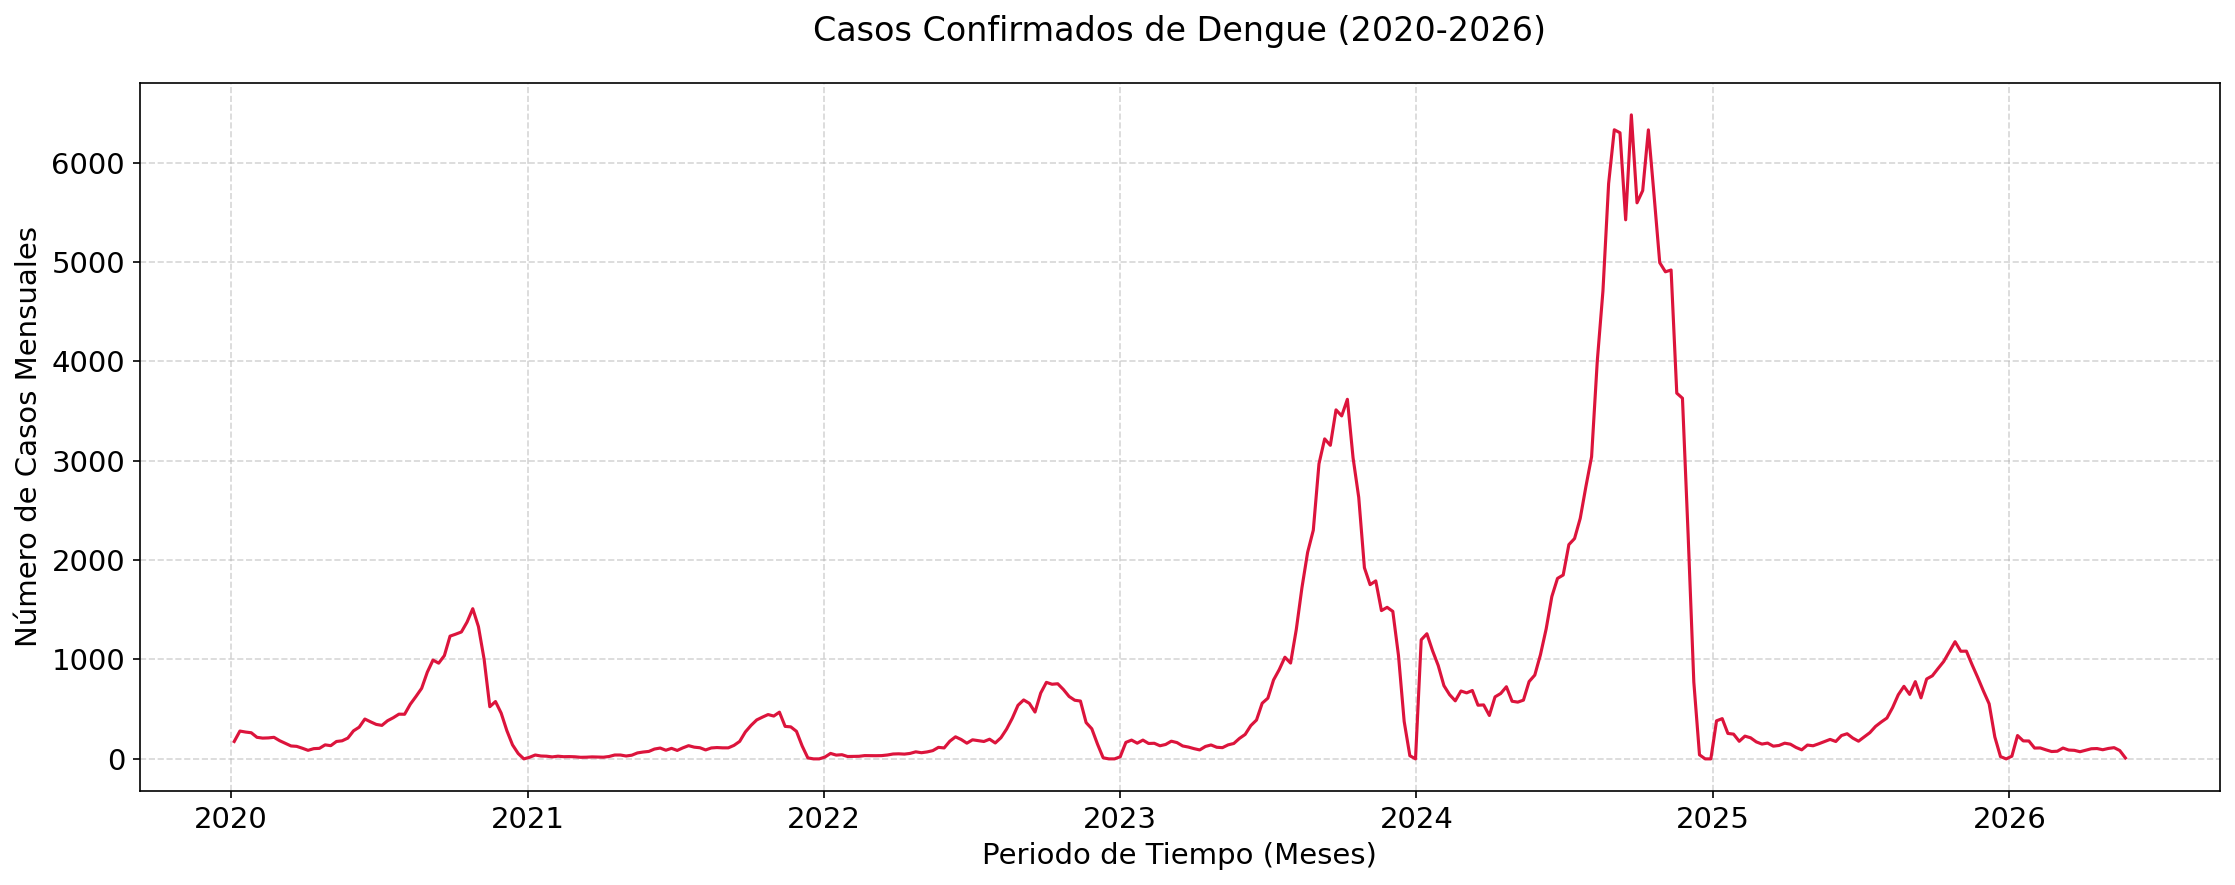

In [4]:
plt.figure(figsize=(15, 6), dpi=150)
plt.plot(datos["FECHA"],datos.drop('FECHA',axis=1).sum(axis=1), color='crimson')

plt.title('Casos Confirmados de Dengue (2020-2026)', fontsize=16, pad=20)
plt.xlabel('Periodo de Tiempo (Meses)', fontsize=14)
plt.ylabel('Número de Casos Mensuales', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tick_params(labelsize=14)

plt.tight_layout()
plt.show()

## Diferencias de escala entre las variables

Aunque todas las variables representan el mismo tipo de cantidad —número de casos semanales de dengue—, esto no implica que tengan la misma escala.

Para cada entidad podemos estudiar, por ejemplo:

- media de casos semanales;
- desviación estándar;
- valor máximo observado;
- proporción de semanas con cero casos.

La desviación estándar es especialmente importante porque mide la variabilidad de cada variable:

$$
s_j
=
\sqrt{
\frac{1}{n-1}
\sum_{i=1}^{n}
(x_{ij}-\bar{x}_j)^2
}.
$$

Si algunas entidades presentan una variabilidad mucho mayor que otras, tendrán mayor influencia en métodos basados en varianzas y covarianzas.

Esto es particularmente importante para el **Análisis de Componentes Principales**, ya que PCA busca direcciones que expliquen la mayor cantidad posible de variabilidad.

Por tanto, antes de aplicar PCA debemos preguntarnos: ¿Queremos que una entidad tenga mayor influencia simplemente porque registra números más grandes?

Para responder esta pregunta, primero examinaremos las escalas de las 32 variables.

In [5]:
# Variables correspondientes a las entidades
estados = [columna for columna in datos.columns if columna != "FECHA"]

# Resumen por entidad
resumen_estados = pd.DataFrame({
    "media": datos[estados].mean(),
    "desv_std": datos[estados].std(),
    "maximo": datos[estados].max(),
    "porc_ceros": datos[estados].eq(0).mean().mul(100)})

# Ordenamos de mayor a menor variabilidad
resumen_estados = resumen_estados.sort_values("desv_std",ascending=False)
resumen_estados.round(2)

,media,desv_std,maximo,porc_ceros
JALISCO,87.88,240.48,1643,16.17
NUEVO LEON,39.47,134.98,841,47.01
VERACRUZ,75.85,133.12,826,4.79
YUCATAN,34.47,132.58,1018,40.42
MORELOS,37.20,77.75,441,16.47
COAHUILA,27.13,75.34,529,60.78
GUERRERO,37.23,74.14,538,10.18
SONORA,24.46,65.95,495,51.20
SINALOA,30.02,65.30,458,12.28
MICHOACAN,34.81,60.92,408,9.28


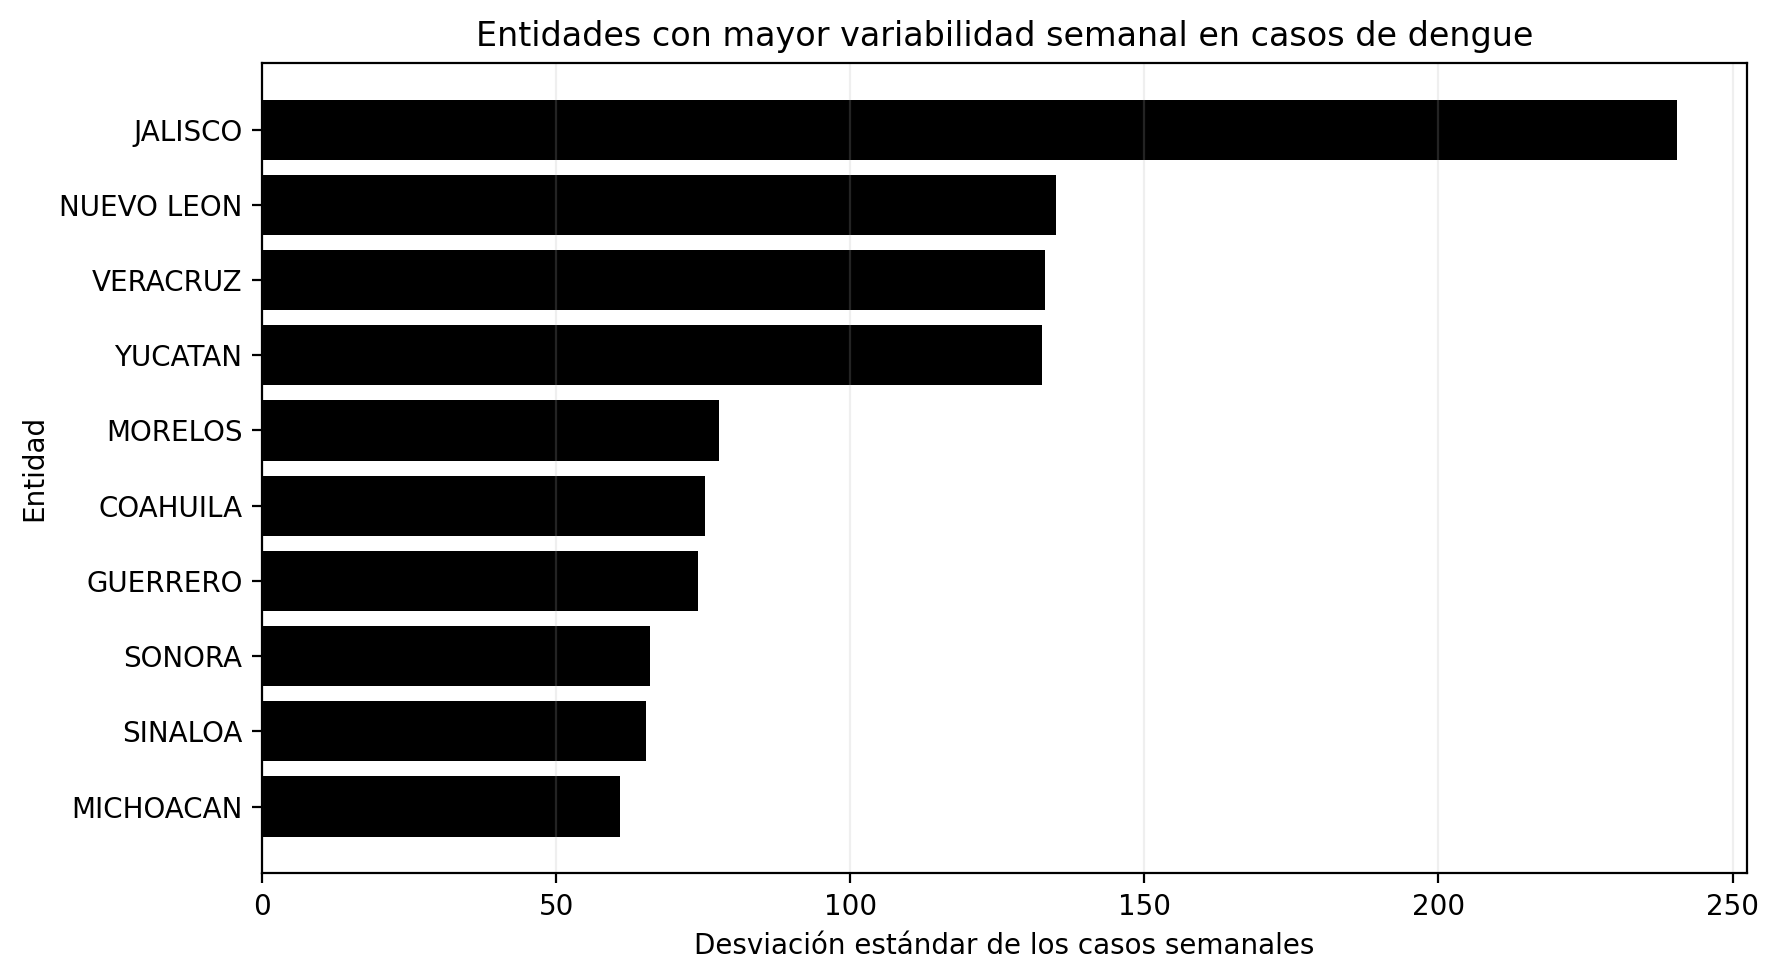

In [6]:
top_10 = resumen_estados.head(10).sort_values("desv_std")

fig, ax = plt.subplots(figsize=(9, 5),dpi=200)

ax.barh(top_10.index,top_10["desv_std"], color='black')

ax.set_title("Entidades con mayor variabilidad semanal en casos de dengue")
ax.set_xlabel("Desviación estándar de los casos semanales")
ax.set_ylabel("Entidad")
ax.grid(axis="x",alpha=0.2)

plt.tight_layout()
plt.show()

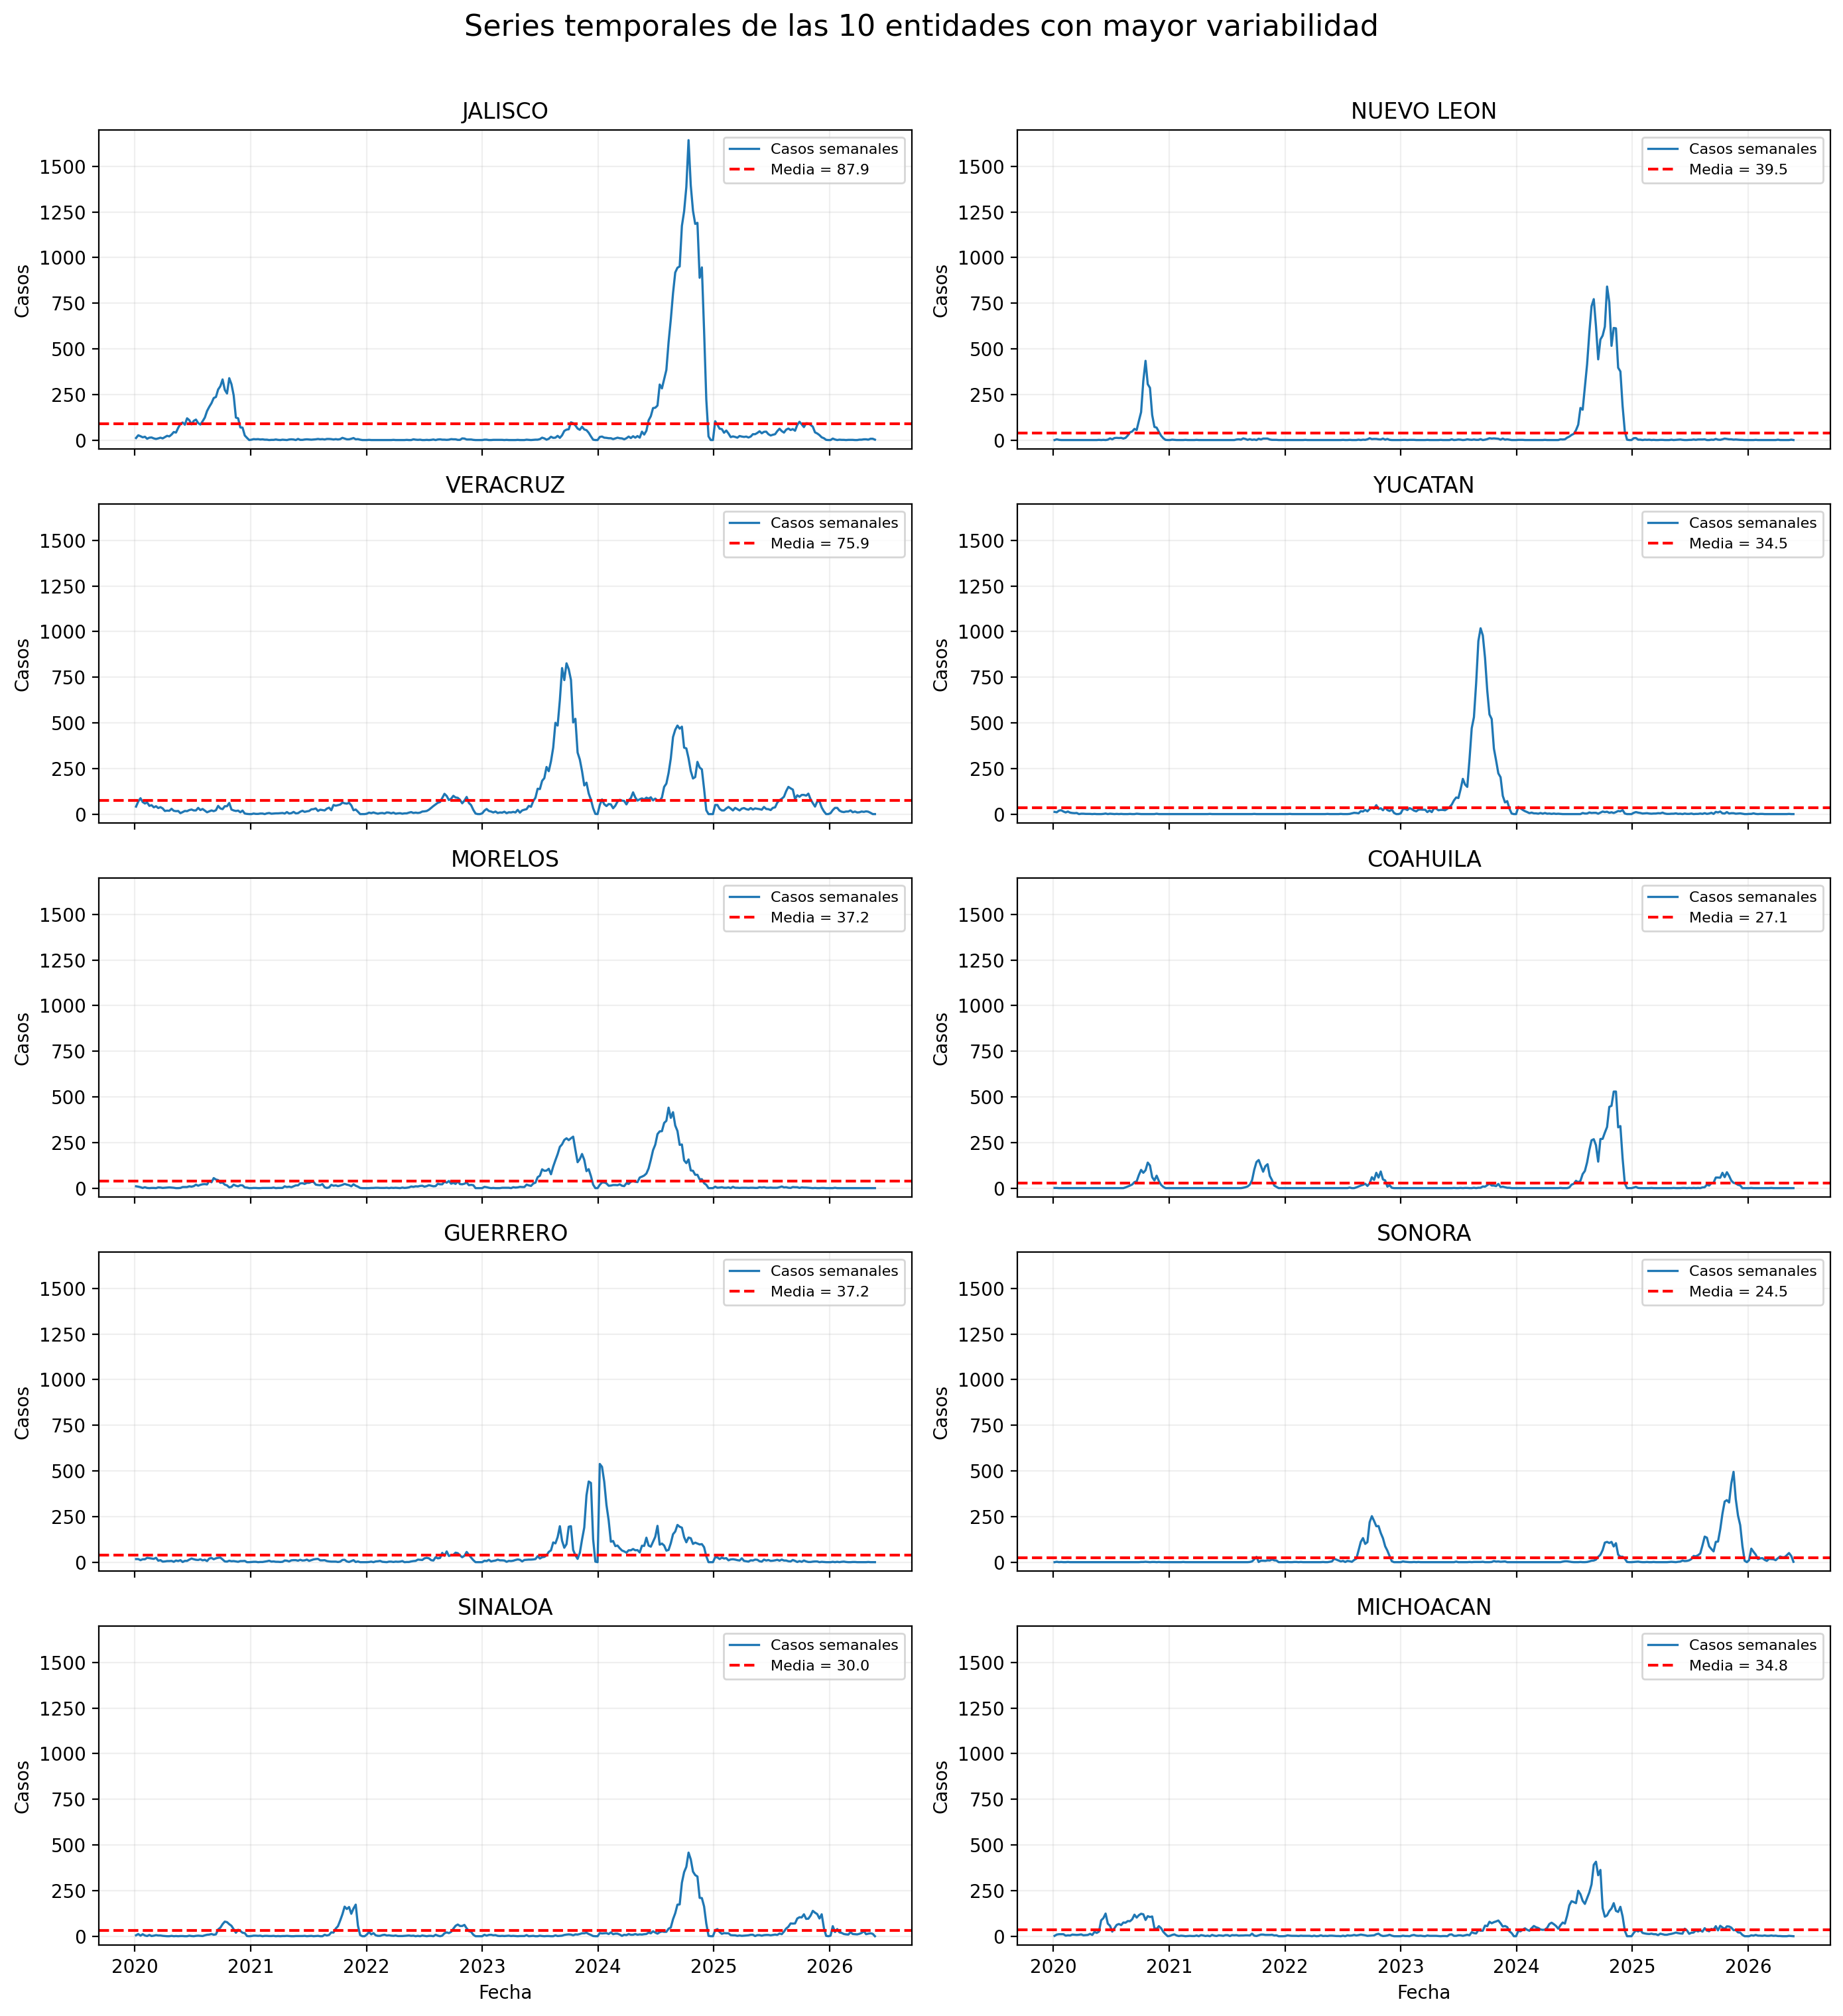

In [7]:
estados_top10 = top_10.sort_values("desv_std", ascending=False).index.tolist()

fig, axes = plt.subplots(5,2,figsize=(14, 15),sharex=True, dpi=200)

axes = axes.flatten()

for ax, estado in zip(axes, estados_top10):

    ax.plot(datos["FECHA"],datos[estado],linewidth=1.2,label="Casos semanales")

    media_estado = datos[estado].mean()

    ax.axhline(
        media_estado,
        linestyle="--",
        linewidth=1.5,
        label=f"Media = {media_estado:.1f}",
        color='red'
    )

    ax.set_title(estado)
    ax.set_ylabel("Casos")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
    ax.set_ylim(-50, 1700)

for ax in axes[-2:]:
    ax.set_xlabel("Fecha")


fig.suptitle("Series temporales de las 10 entidades con mayor variabilidad",fontsize=16,y=1.01)
plt.tight_layout()
plt.show()

## Estandarización de las variables

Las entidades presentan escalas y niveles de variabilidad muy diferentes.

Por ejemplo, en nuestros datos:

- Jalisco presenta una desviación estándar superior a $240$ casos;
- Nuevo León y Veracruz superan los $130$;
- otras entidades presentan desviaciones estándar mucho menores.

Esto es importante porque el Análisis de Componentes Principales busca direcciones que maximicen la varianza.

Si aplicamos PCA directamente sobre las variables originales, las entidades con mayor variabilidad pueden dominar los primeros componentes.

Para evitar este efecto podemos **estandarizar** cada variable.

Para una variable $X_j$, definimos

$$
Z_j
=
\frac{X_j-\bar X_j}{s_j},
$$

donde:

- $\bar X_j$ es la media de la variable;
- $s_j$ es su desviación estándar.

Después de esta transformación, cada variable queda expresada en términos de **desviaciones estándar respecto a su propia media**.

Una observación

$$
Z_{ij}=2
$$

significa que el valor observado se encuentra aproximadamente dos desviaciones estándar por encima de la media de esa entidad.

Después de estandarizar esperamos aproximadamente:

$$
\bar Z_j=0
$$

y

$$
s_{Z_j}=1.
$$

De esta manera, las variables comienzan el análisis en una escala comparable.

In [8]:
# Matriz de variables
X = datos[estados].copy()


# Estandarización

scaler = StandardScaler()

X_std = scaler.fit_transform(X)


# Convertimos a DataFrame
X_std = pd.DataFrame(
    X_std,
    columns=estados,
    index=datos.index
)


# Verificación
resumen_estandarizado = pd.DataFrame({
    "media_original": X.mean(),
    "std_original": X.std(ddof=0),

    "media_estandarizada": X_std.mean(),
    "std_estandarizada": X_std.std(ddof=0)
})


resumen_estandarizado.round(3)

,media_original,std_original,media_estandarizada,std_estandarizada
AGUASCALIENTES,11.075,45.957,-0.0,1.0
BAJA CALIFORNIA,0.910,2.620,-0.0,1.0
BAJA CALIFORNIA SUR,12.620,30.023,-0.0,1.0
CAMPECHE,8.153,28.213,-0.0,1.0
CHIAPAS,29.850,48.339,0.0,1.0
CHIHUAHUA,1.084,5.473,0.0,1.0
COAHUILA,27.132,75.227,0.0,1.0
COLIMA,19.036,46.686,0.0,1.0
DISTRITO FEDERAL,1.695,3.657,0.0,1.0
DURANGO,4.237,17.844,-0.0,1.0


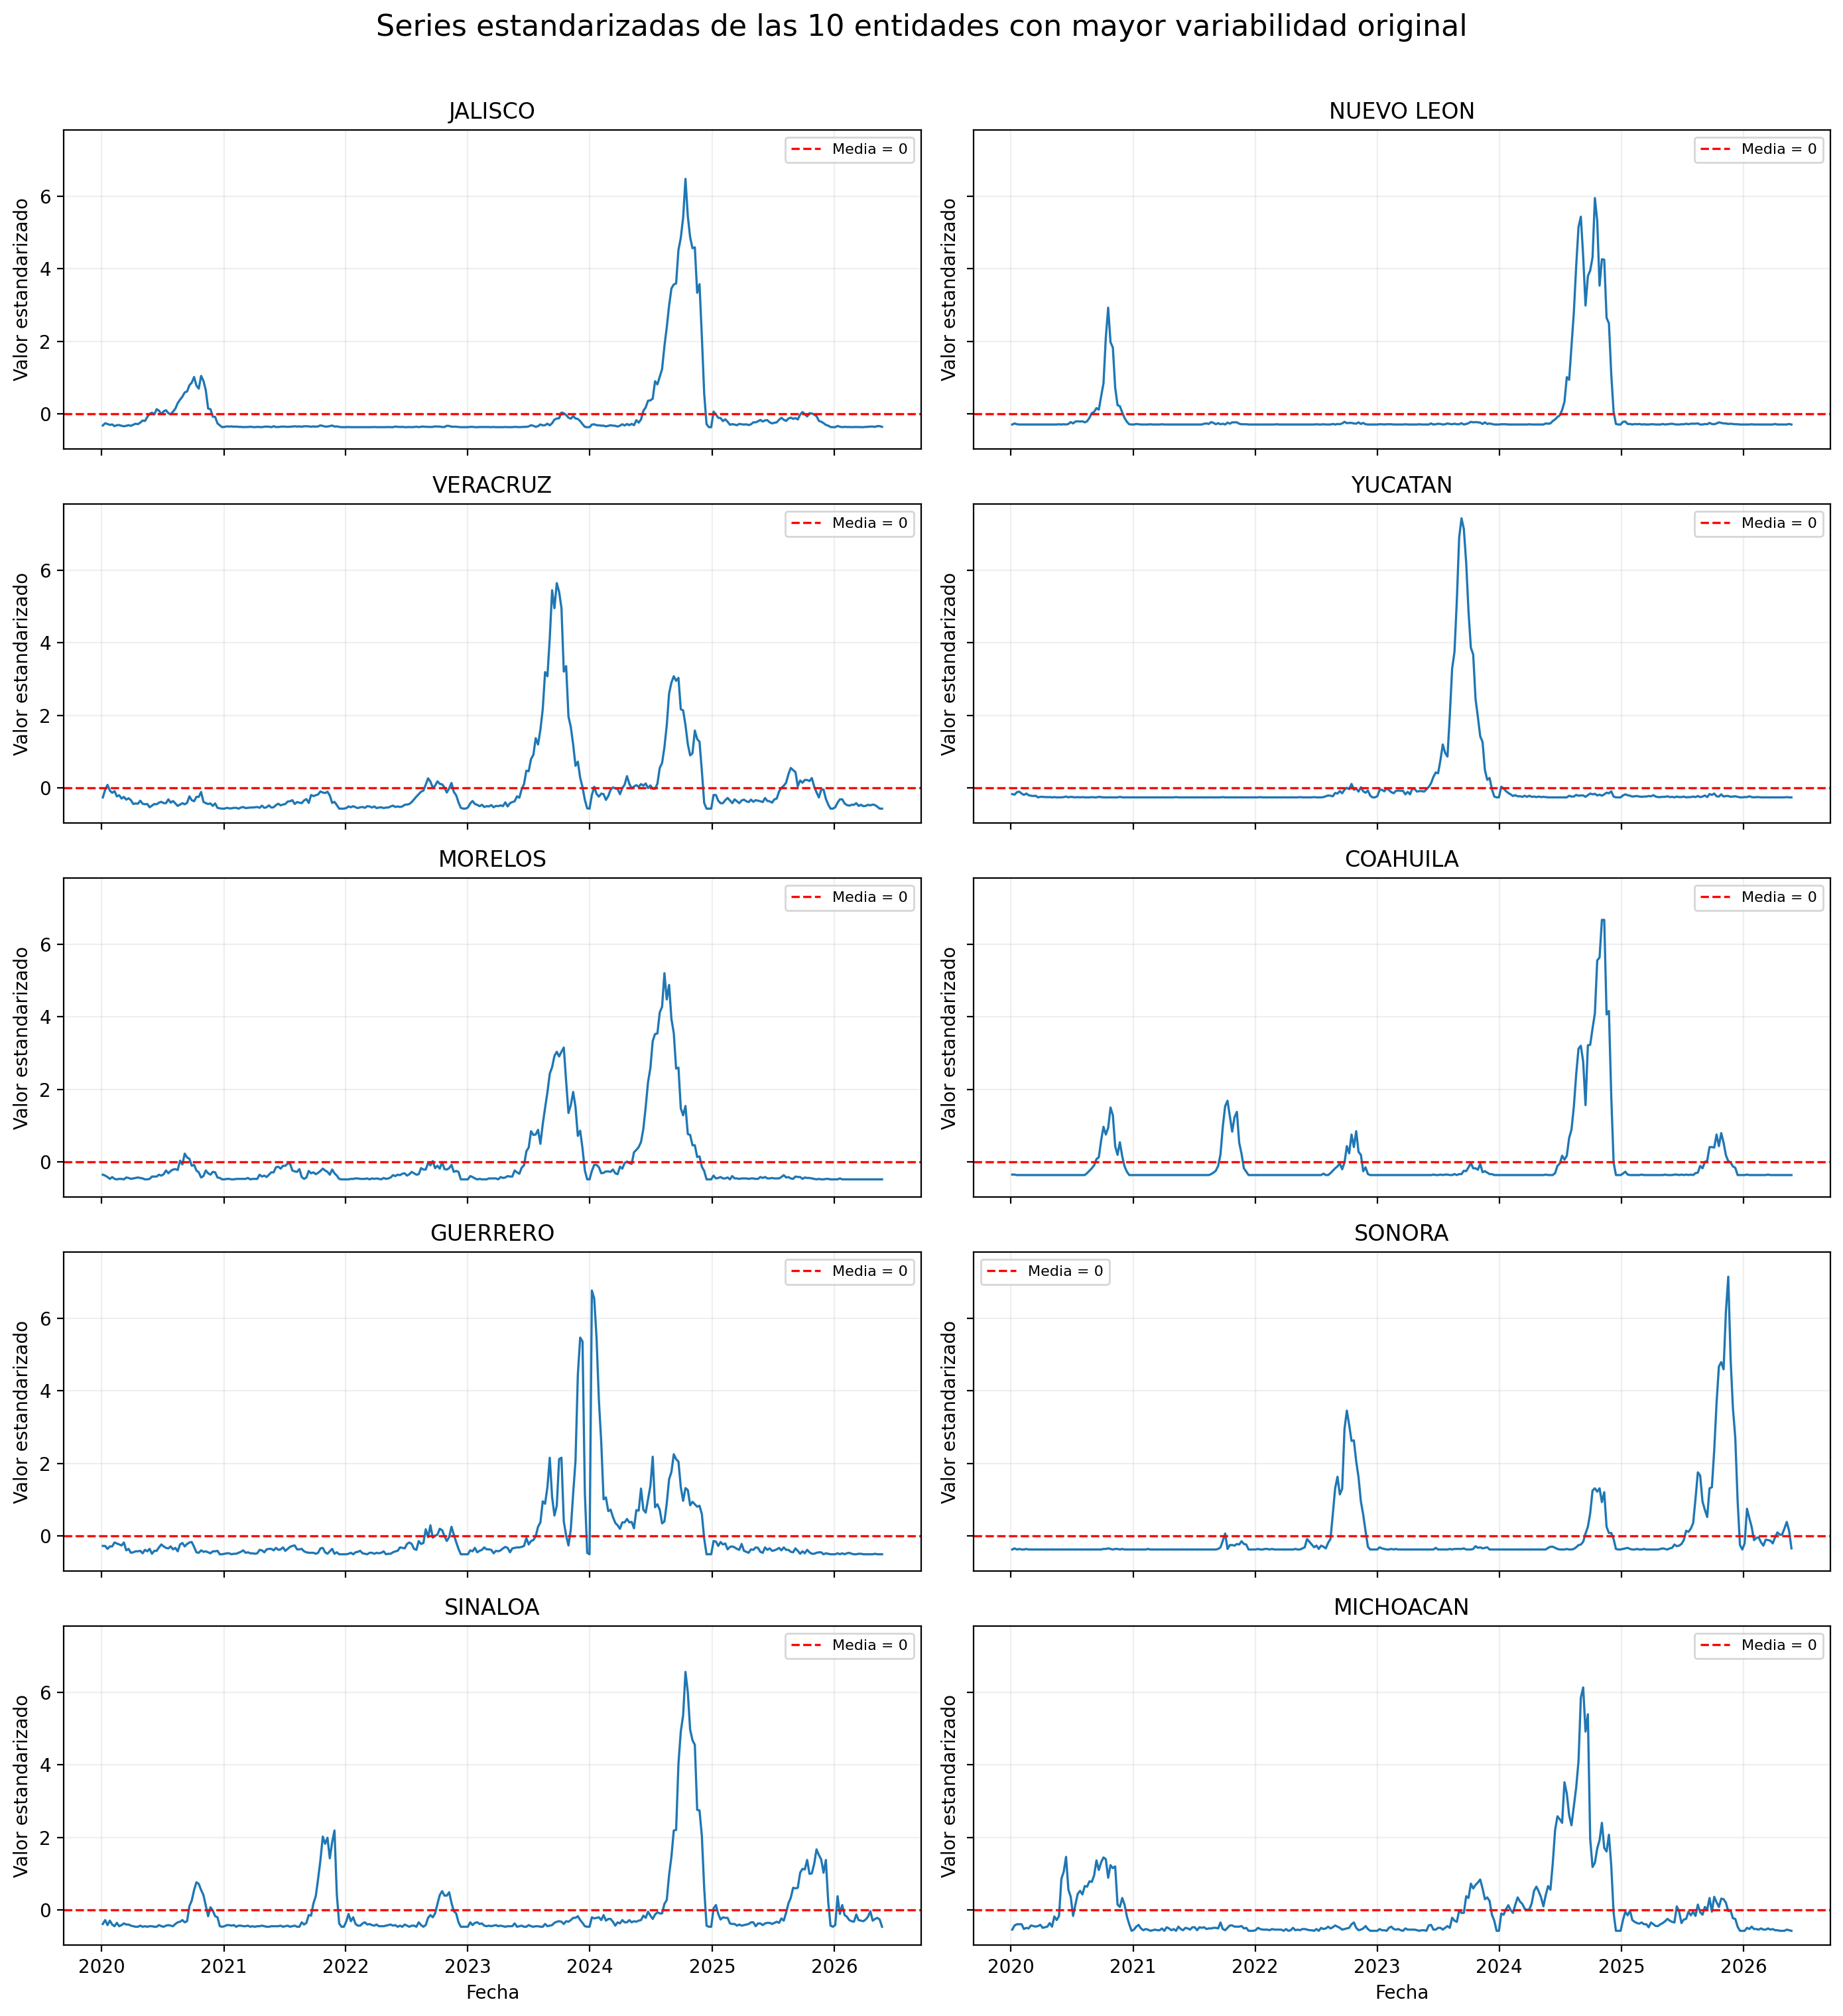

In [9]:
estados_top10 = resumen_estados.head(10).index.tolist()


fig, axes = plt.subplots(5,2,figsize=(14, 15),sharex=True,sharey=True, dpi=200)

axes = axes.flatten()

for ax, estado in zip(axes,estados_top10):

    ax.plot(datos["FECHA"],X_std[estado],linewidth=1.2)
    ax.axhline(0,linestyle="--",linewidth=1.2,label="Media = 0",color='red')
    ax.set_title(estado)
    ax.set_ylabel("Valor estandarizado")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)


for ax in axes[-2:]:
    ax.set_xlabel("Fecha")


fig.suptitle(
    "Series estandarizadas de las 10 entidades "
    "con mayor variabilidad original",fontsize=16,y=1.01)

plt.tight_layout()
plt.show()

### Resultado de la estandarización

La transformación produjo, para todas las entidades,

$$
\bar Z_j \approx 0
$$

y

$$
s_{Z_j}\approx 1.
$$

Esto significa que las diferencias originales de escala fueron eliminadas.

Por ejemplo, antes de estandarizar:

$$
s_{\text{Jalisco}}\approx 240.12,
$$

mientras que

$$
s_{\text{Tlaxcala}}\approx 0.43.
$$

Por tanto, sus niveles de variabilidad eran extremadamente diferentes.

Después de la estandarización ambas variables tienen:

$$
s=1.
$$

Ahora un valor estandarizado debe interpretarse en relación con el comportamiento habitual de cada entidad.

Por ejemplo,

$$
Z=3
$$

significa que el número de casos observado se encuentra tres desviaciones estándar por encima de la media de esa entidad.

La estandarización **no elimina la forma temporal ni los episodios extremos**. Únicamente cambia la escala con la que representamos cada variable.

## Covarianza y correlación

El Análisis de Componentes Principales estudia cómo varían conjuntamente las variables.

Una medida básica de esta relación es la **covarianza**.

Para dos variables $X$ y $Y$:

$$
\operatorname{Cov}(X,Y)
=
\frac{1}{n-1}
\sum_{i=1}^{n}
(X_i-\bar X)
(Y_i-\bar Y).
$$

Una covarianza positiva indica que ambas variables tienden a aumentar conjuntamente, mientras que una covarianza negativa indica que una tiende a aumentar cuando la otra disminuye.

Sin embargo, la magnitud de la covarianza depende de las escalas de las variables.

La **correlación** elimina este efecto:

$$
\rho_{XY}
=
\frac{
\operatorname{Cov}(X,Y)
}{
s_Xs_Y
}.
$$

Por ello,

$$
-1\leq\rho_{XY}\leq1.
$$

Existe una relación fundamental: **La matriz de covarianzas de las variables estandarizadas es equivalente,** salvo pequeñas diferencias debidas a la definición muestral o poblacional de la varianza, **a la matriz de correlaciones de las variables originales.**

Por esta razón, realizar PCA sobre variables estandarizadas equivale conceptualmente a realizar PCA utilizando la estructura de correlaciones entre las variables.

In [10]:
# Matriz de covarianzas de los datos originales
cov_original = X.cov()

# Matriz de correlaciones de los datos originales
corr_original = X.corr()


# Matriz de covarianzas de los datos estandarizados
cov_estandarizada = X_std.cov()


print("Rango de las covarianzas originales:")
print(f"{cov_original.values.min():.2f}", "a", f"{cov_original.values.max():.2f}")

print("\nRango de las correlaciones:")
print(f"{corr_original.values.min():.3f}", "a", f"{corr_original.values.max():.3f}")


# Comparación entre correlación original y covarianza estandarizada
diferencia = (corr_original - cov_estandarizada).abs()

print("\nMáxima diferencia absoluta entre correlación original y covarianza estandarizada:")
print(diferencia.values.max())

Rango de las covarianzas originales:
-1227.85 a 57830.87

Rango de las correlaciones:
-0.132 a 1.000

Máxima diferencia absoluta entre correlación original y covarianza estandarizada:
0.0030030030030077093


## Análisis de Componentes Principales

Tenemos actualmente $p=32$ variables:

$$
X_1,X_2,\ldots,X_{32},
$$

una por cada entidad federativa.

El objetivo del **Análisis de Componentes Principales (PCA)** es construir nuevas variables que resuman la información contenida en las variables originales.

Estas nuevas variables se denominan **componentes principales**.

El primer componente principal es una combinación lineal de las variables estandarizadas:

$$
PC_1
=
a_{11}Z_1
+
a_{12}Z_2
+\cdots+
a_{1p}Z_p.
$$

El segundo componente tiene la forma

$$
PC_2
=
a_{21}Z_1
+
a_{22}Z_2
+\cdots+
a_{2p}Z_p.
$$

y así sucesivamente.

Los coeficientes

$$
a_{jk}
$$

determinan cuánto contribuye cada variable original al componente.



### ¿Cómo se eligen los componentes?

El primer componente se elige de manera que capture la **mayor cantidad posible de variabilidad** de los datos.

El segundo componente captura la mayor cantidad posible de la variabilidad restante y, además, es ortogonal al primero.

De forma similar:

$$
PC_1 \perp PC_2 \perp \cdots \perp PC_p.
$$

Por tanto:

- $PC_1$ explica la mayor cantidad de variabilidad;
- $PC_2$ explica la mayor cantidad posible de la variabilidad restante;
- los componentes posteriores explican progresivamente menos.



### Varianza explicada

A cada componente principal le corresponde un valor

$$
\lambda_j,
$$

que representa la varianza capturada por ese componente.

La proporción de varianza explicada por el componente $j$ es

$$
\frac{\lambda_j}
{\lambda_1+\lambda_2+\cdots+\lambda_p}.
$$

Si unos pocos componentes explican una proporción grande de la variabilidad total, podremos sustituir las 32 variables originales por un número mucho menor de componentes.

Esto se conoce como **reducción de dimensionalidad**.

In [11]:
# PCA

pca = PCA()

scores = pca.fit_transform(X_std)


# Información de cada componente

varianza_explicada = pca.explained_variance_ratio_

varianza_acumulada = np.cumsum(varianza_explicada)

resumen_pca = pd.DataFrame({
    "componente": [f"PC{i}" for i in range(1, len(varianza_explicada) + 1)],

    "varianza_explicada": varianza_explicada,

    "varianza_acumulada": varianza_acumulada})

resumen_pca.head(15).round(4)

,componente,varianza_explicada,varianza_acumulada
0,PC1,0.5131,0.5131
1,PC2,0.1592,0.6723
2,PC3,0.0790,0.7513
3,PC4,0.0415,0.7928
4,PC5,0.0353,0.8281
5,PC6,0.0278,0.8558
6,PC7,0.0239,0.8797
7,PC8,0.0207,0.9004
8,PC9,0.0167,0.9171
9,PC10,0.0145,0.9316


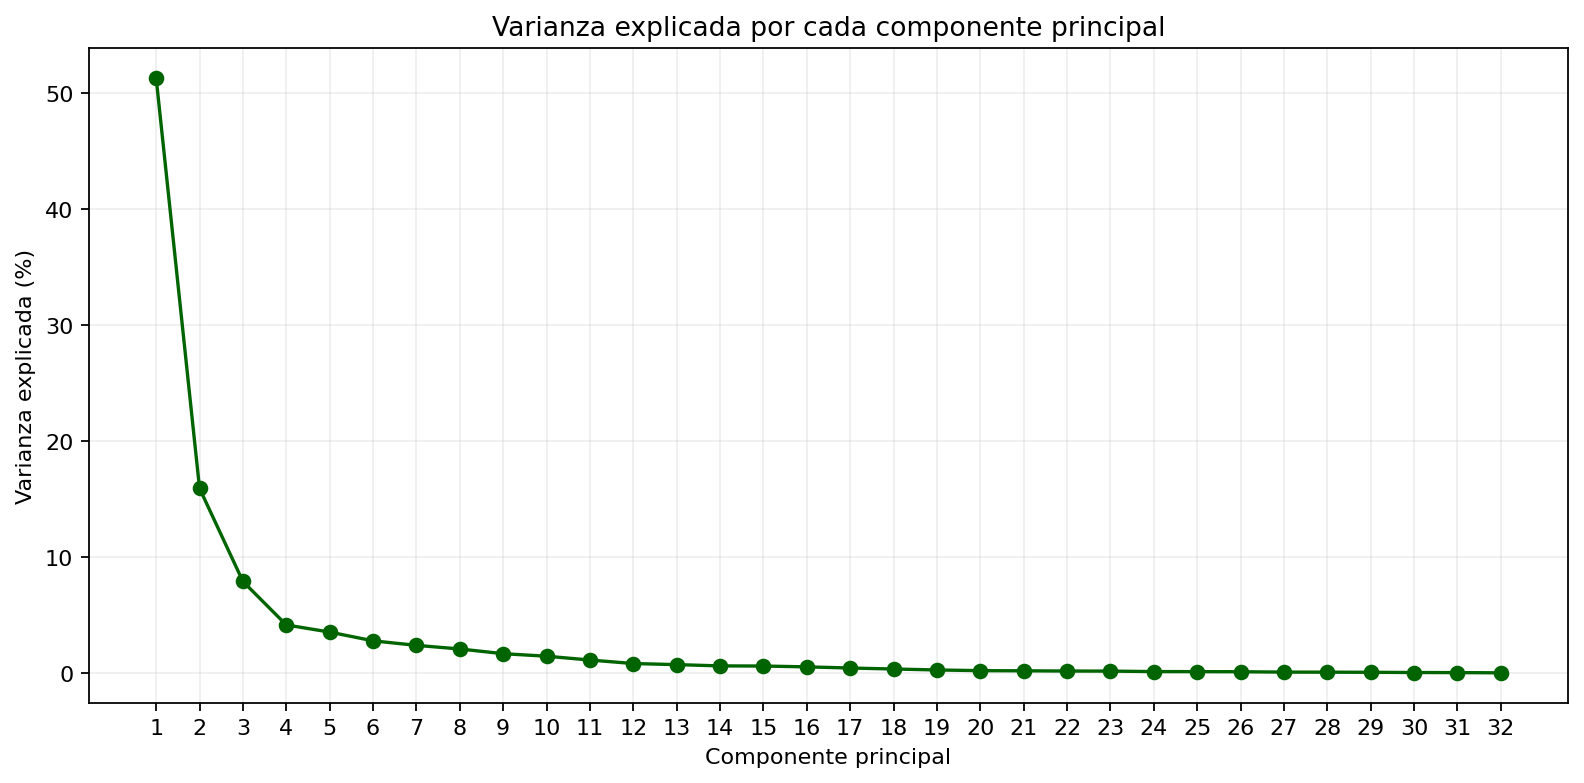

In [12]:
componentes = np.arange(1, len(varianza_explicada) + 1)

fig, ax = plt.subplots(figsize=(10, 5), dpi=160)

ax.plot(componentes, varianza_explicada * 100, marker="o",linewidth=1.5, color='darkgreen')

ax.set_title("Varianza explicada por cada componente principal")
ax.set_xlabel("Componente principal")
ax.set_ylabel("Varianza explicada (%)")
ax.set_xticks(componentes)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

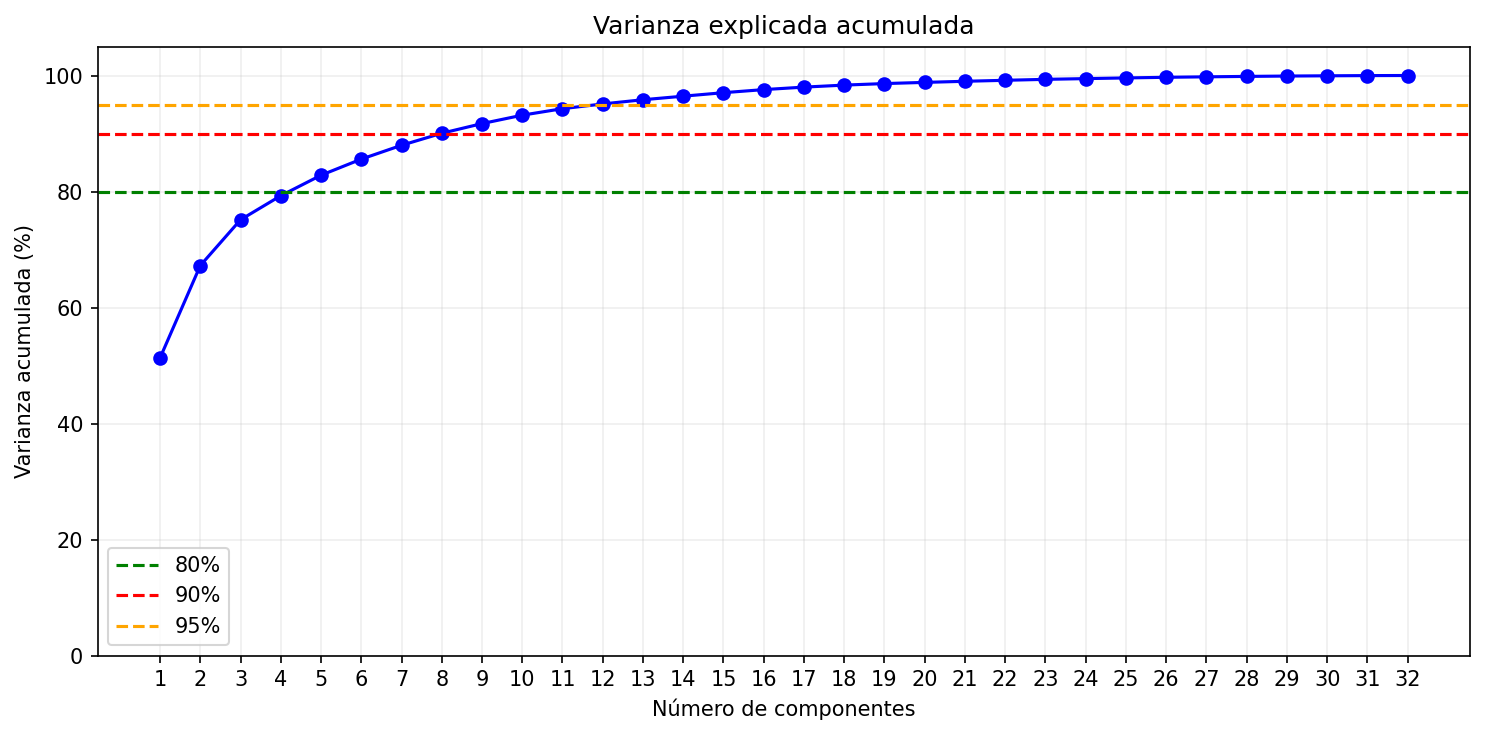

In [14]:
# Varianza explicada acumulada
fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

ax.plot(componentes,varianza_acumulada * 100,marker="o",linewidth=1.5, color='blue')

ax.axhline(80,linestyle="--",label="80%", color='green')
ax.axhline(90,linestyle="--",label="90%", color='red')
ax.axhline(95,linestyle="--",label="95%", color='orange')

ax.set_title("Varianza explicada acumulada")
ax.set_xlabel("Número de componentes")
ax.set_ylabel("Varianza acumulada (%)")
ax.set_xticks(componentes)
ax.set_ylim(0,105)
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

### ¿Cuántos componentes necesitamos?

El primer componente principal explica $51.31\%$ de la variabilidad total. El segundo componente explica adicionalmente $15.92\%,$ por lo que los dos primeros componentes acumulan $67.23\%.$ Al incorporar el tercer componente alcanzamos$75.13\%.$

La varianza acumulada permite determinar cuántos componentes serían necesarios para conservar diferentes cantidades de información:

$$
\begin{array}{c|c}
\text{Varianza conservada} & \text{Número de componentes}\\
\hline
80\% & 5\\
90\% & 8\\
95\% & 12
\end{array}
$$

Por ejemplo, conservar el $90\%$ de la variabilidad permitiría pasar de

$$
32\text{ variables}
$$

a solamente

$$
8\text{ componentes}.
$$

Esto representa una reducción de dimensionalidad de

$$
32\longrightarrow8.
$$

Conocer cuánta variabilidad explica cada componente no nos dice todavía **qué representa cada componente**.

Para ello debemos estudiar los coeficientes asociados con las variables originales.

## ¿Qué significa un componente principal?

El primer componente principal es una combinación lineal de las variables estandarizadas:

$$
PC_1
=
a_{11}Z_1
+
a_{12}Z_2
+\cdots+
a_{1,32}Z_{32}.
$$

Los coeficientes

$$
a_{11},a_{12},\ldots,a_{1,32}
$$

indican la participación de cada entidad en el primer componente.

De manera similar,

$$
PC_2
=
a_{21}Z_1
+
a_{22}Z_2
+\cdots+
a_{2,32}Z_{32}.
$$

Un coeficiente con gran valor absoluto indica que la variable tiene una participación importante en ese componente.

Por tanto, para estudiar un componente debemos observar:

1. la **magnitud** de los coeficientes;
2. su **signo**;
3. qué variables presentan patrones similares.

Dos variables con coeficientes del mismo signo contribuyen en la misma dirección al componente, mientras que coeficientes con signos opuestos producen un contraste.

Es importante recordar que el signo global de un componente principal es arbitrario: $PC_j$
 y $-PC_j$ representan exactamente la misma dirección.

Por ello, la interpretación debe centrarse principalmente en las magnitudes relativas y en los signos de unas variables respecto a otras.

In [15]:
# Coeficientes de los componentes principales

pesos_pca = pd.DataFrame(
    pca.components_.T,
    index=estados,
    columns=[f"PC{i}" for i in range(1, len(estados) + 1)])


# PC1
pesos_pc1 = (
    pesos_pca[["PC1"]]
    .assign(abs_PC1=lambda x: x["PC1"].abs())
    .sort_values("abs_PC1", ascending=False)
)


# PC2
pesos_pc2 = (
    pesos_pca[["PC2"]]
    .assign(abs_PC2=lambda x: x["PC2"].abs())
    .sort_values("abs_PC2",ascending=False)
)


print("Variables con mayor peso en PC1:")
display(pesos_pc1.head(10).round(3))


print("\nVariables con mayor peso en PC2:")
display(pesos_pc2.head(10).round(3))

Variables con mayor peso en PC1:


,PC1,abs_PC1
COLIMA,0.230,0.230
JALISCO,0.224,0.224
NUEVO LEON,0.222,0.222
GUANAJUATO,0.222,0.222
HIDALGO,0.221,0.221
NAYARIT,0.220,0.220
BAJA CALIFORNIA SUR,0.220,0.220
PUEBLA,0.219,0.219
QUERETARO,0.217,0.217
DURANGO,0.215,0.215



Variables con mayor peso en PC2:


,PC2,abs_PC2
CAMPECHE,0.359,0.359
QUINTANA ROO,0.357,0.357
YUCATAN,0.352,0.352
TABASCO,0.289,0.289
VERACRUZ,0.273,0.273
CHIAPAS,0.253,0.253
MORELOS,0.222,0.222
SINALOA,-0.194,0.194
GUERRERO,0.184,0.184
COAHUILA,-0.174,0.174


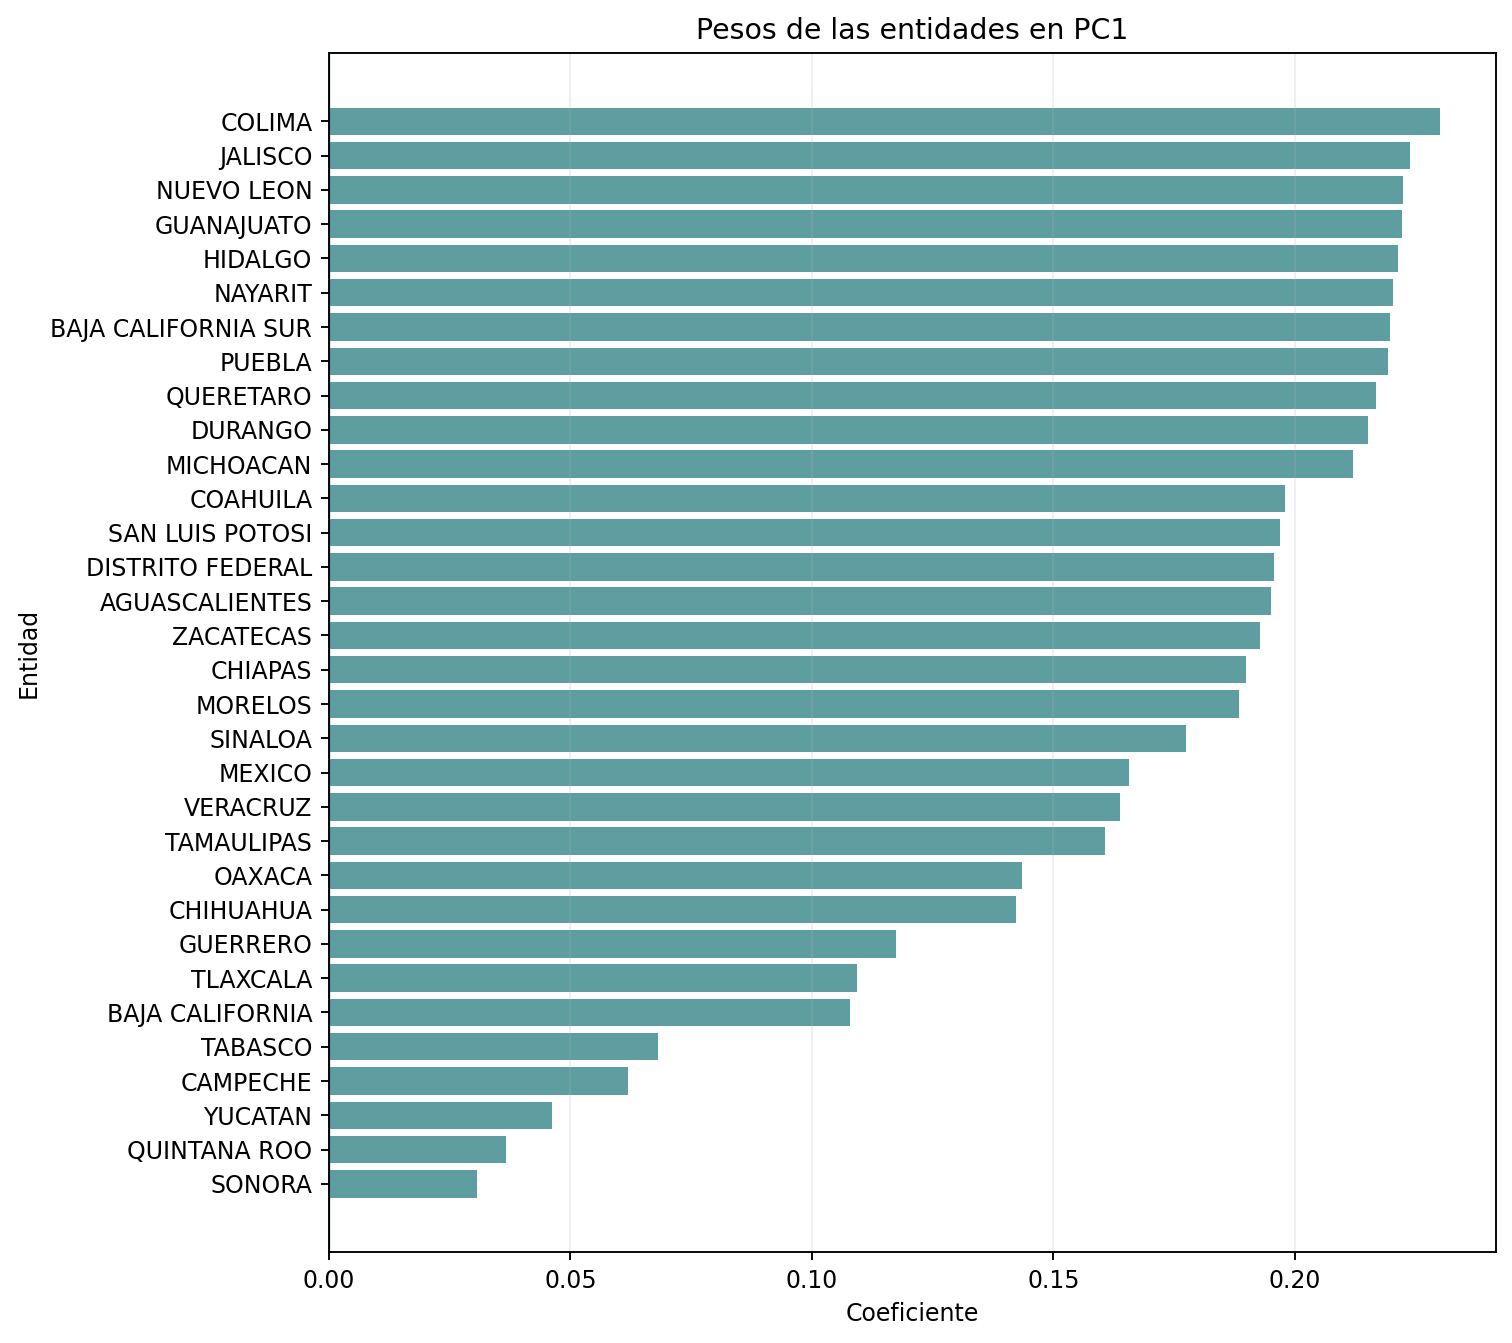

In [16]:
# Pesos de PC1

pc1_ordenado = pesos_pca["PC1"].sort_values()

fig, ax = plt.subplots(figsize=(9, 8),dpi=170)

ax.barh(pc1_ordenado.index,pc1_ordenado.values, color='cadetblue')

ax.axvline(0,linewidth=1)
ax.set_title("Pesos de las entidades en PC1")
ax.set_xlabel("Coeficiente")
ax.set_ylabel("Entidad")
ax.grid(axis="x",alpha=0.2)

plt.tight_layout()
plt.show()



En $PC_1$, todos los coeficientes son positivos. Eso es muy importante: el primer componente no está contrastando grupos de estados, sino capturando un **patrón común de intensidad de dengue**. Semanas con valores altos de $PC_1$ tenderán a ser semanas en las que muchas entidades presentan valores estandarizados altos simultáneamente. Colima, Jalisco, Nuevo León, Guanajuato, Hidalgo, Nayarit y Baja California Sur aparecen entre las variables con mayor peso, pero la señal está bastante distribuida entre muchas entidades.


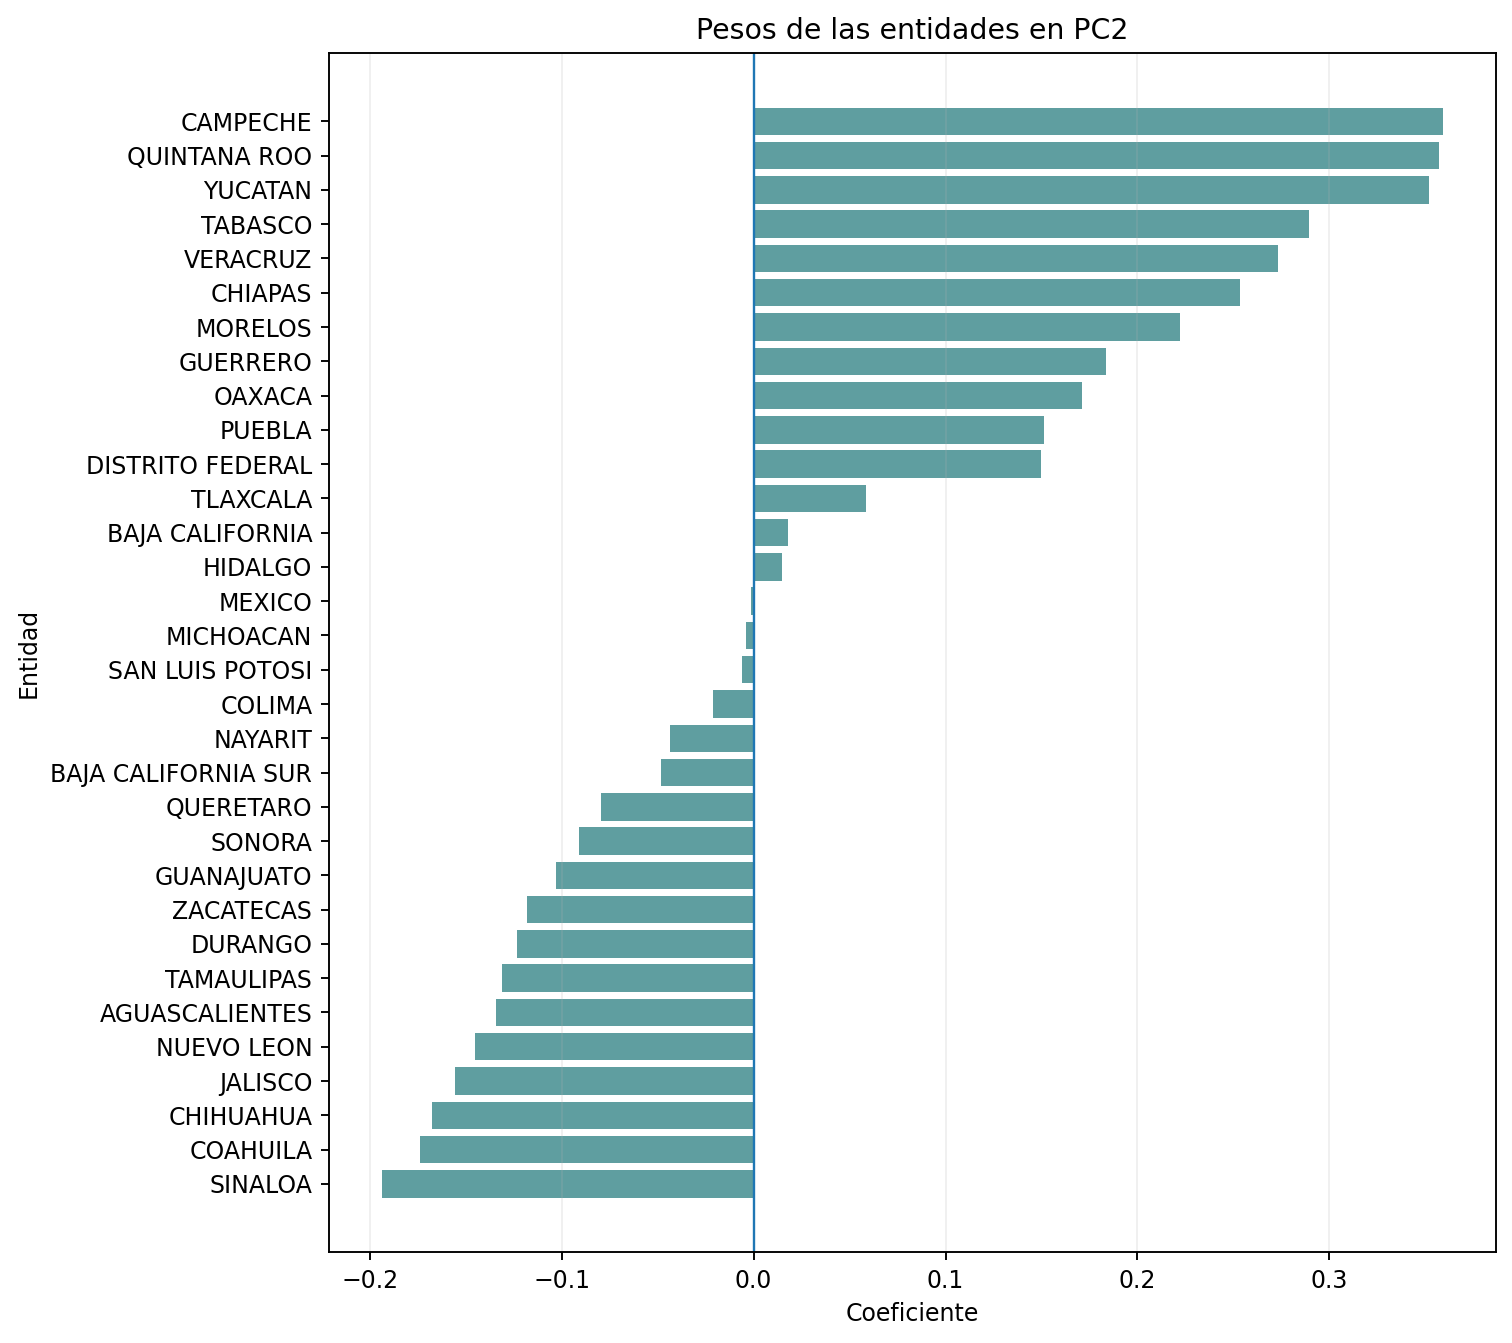

In [17]:
# Pesos de PC2

pc2_ordenado = pesos_pca["PC2"].sort_values()

fig, ax = plt.subplots(figsize=(9, 8),dpi=170)

ax.barh(pc2_ordenado.index,pc2_ordenado.values, color='cadetblue')

ax.axvline(0,linewidth=1)
ax.set_title("Pesos de las entidades en PC2")
ax.set_xlabel("Coeficiente")
ax.set_ylabel("Entidad")
ax.grid(axis="x",alpha=0.2)

plt.tight_layout()
plt.show()

En $PC_2$: Campeche, Quintana Roo, Yucatán, Tabasco, Veracruz y Chiapas tienen pesos positivos relativamente grandes, mientras que Sinaloa, Coahuila, Chihuahua, Jalisco y Nuevo León aparecen con pesos negativos. Por tanto, $PC_2$ parece distinguir **dos patrones temporales diferentes entre conjuntos de entidades**. Conviene describirlo así y no asignarle todavía una causa climática, geográfica o epidemiológica específica.


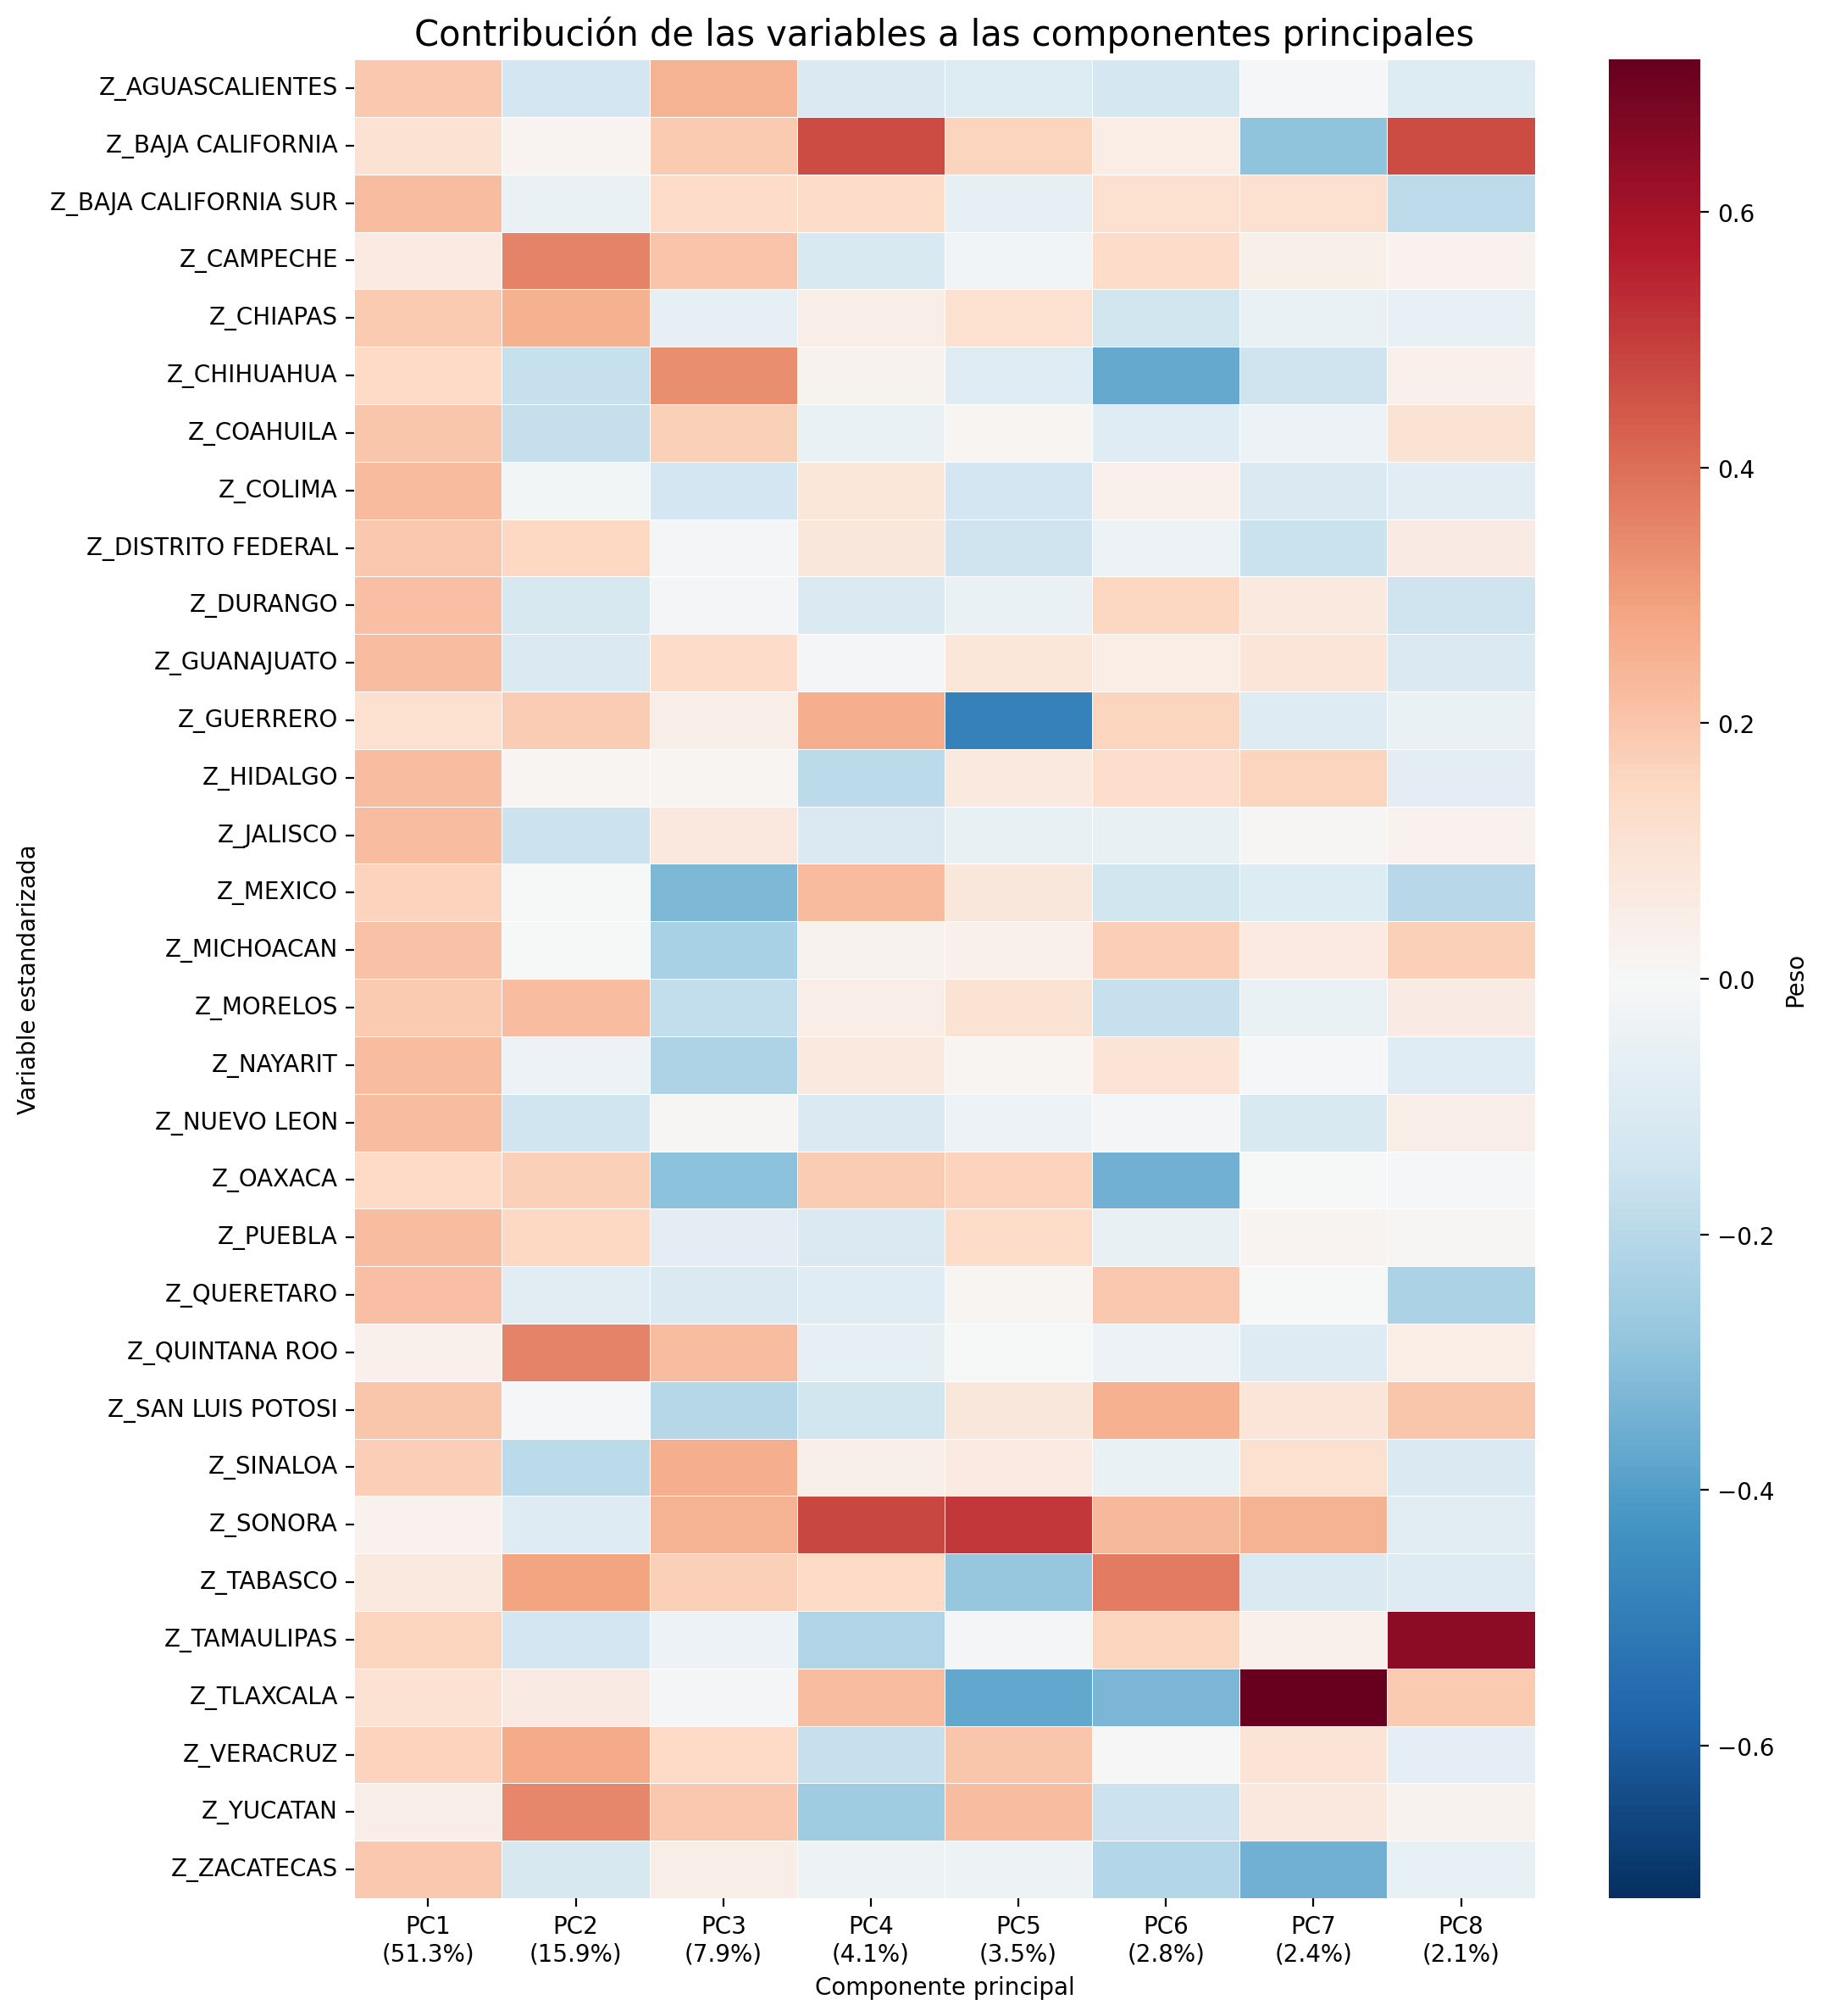

In [18]:
n_componentes = 8

pesos_heatmap = pesos_pca.iloc[:, :n_componentes].copy()
pesos_heatmap.index = [f"Z_{estado}" for estado in pesos_heatmap.index]
pesos_heatmap.columns = [f"PC{i+1}\n({varianza_explicada[i]*100:.1f}%)"
                         for i in range(n_componentes)]

limite = np.abs(pesos_heatmap.to_numpy()).max()


fig, ax = plt.subplots(figsize=(11, 12),dpi=200)

sns.heatmap(
    pesos_heatmap,
    cmap="RdBu_r",
    center=0,
    vmin=-limite,
    vmax=limite,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={"label": "Peso"},
    ax=ax)

ax.set_title("Contribución de las variables a las componentes principales",fontsize=15)
ax.set_xlabel("Componente principal")
ax.set_ylabel("Variable estandarizada")

plt.tight_layout()
plt.show()

El mapa de calor confirma que los componentes posteriores empiezan a estar más dominados por variables concretas: por ejemplo, se observan pesos especialmente intensos para Sonora en componentes intermedios, Tlaxcala en $PC_7$, Tamaulipas en $PC_8$, etc. Esto ayuda a entender por qué $PC_1$ es más “global”, mientras que componentes posteriores representan estructuras más específicas.

### Interpretación de los pesos de las componentes

Los coeficientes de $PC_1$ son positivos para prácticamente todas las entidades.

Esto indica que el primer componente representa principalmente una **dirección común de variación**.

De manera simplificada,

$$
PC_1
\approx
a_1Z_1+a_2Z_2+\cdots+a_{32}Z_{32},
\qquad
a_j>0.
$$

Por tanto, una semana con un valor elevado de $PC_1$ corresponde, en general, a una semana en la que varias entidades presentan valores de dengue superiores a sus respectivos niveles habituales.

Así, $PC_1$ puede interpretarse como una medida sintética de la **intensidad general del dengue entre las entidades**.


El segundo componente presenta una estructura diferente.

Algunas entidades tienen pesos positivos importantes, entre ellas:

- Campeche;
- Quintana Roo;
- Yucatán;
- Tabasco;
- Veracruz;
- Chiapas.

Mientras que otras presentan pesos negativos, por ejemplo:

- Sinaloa;
- Coahuila;
- Chihuahua;
- Jalisco;
- Nuevo León.

Por tanto, $PC_2$ no representa simplemente un aumento general de casos, sino un **contraste entre diferentes patrones de comportamiento temporal**.

Una semana puede presentar un valor elevado de $PC_2$ cuando las entidades con pesos positivos se encuentran relativamente por encima de sus valores habituales y, simultáneamente, las entidades con pesos negativos presentan un comportamiento diferente.



El mapa de calor permite extender esta interpretación a varios componentes.

Cada columna representa una componente principal y cada fila una variable estandarizada.

Los colores más intensos indican coeficientes de mayor magnitud:

$$
|\text{peso grande}|
\quad\Longrightarrow\quad
\text{mayor participación en esa componente}.
$$

Los primeros componentes presentan patrones compartidos por varias entidades, mientras que algunos componentes posteriores están más asociados con comportamientos particulares de determinadas variables.

## Scores: representación de las semanas en el espacio PCA

Los pesos indican cómo se construyen las componentes a partir de las variables originales.

Los **scores**, en cambio, representan las coordenadas de cada observación en las nuevas componentes.

En nuestro conjunto de datos, cada observación corresponde a una semana.

Por tanto, para la semana $t$ obtenemos:

$$
(PC_{1,t},PC_{2,t},\ldots,PC_{32,t}).
$$

Si utilizamos únicamente los dos primeros componentes, cada semana puede representarse como un punto:

$$
(PC_{1,t},PC_{2,t}).
$$

Como $PC_1+PC_2$ explican conjuntamente el

$$
67.23\%
$$

de la variabilidad total, esta representación bidimensional conserva una parte importante de la estructura original de los datos.

El objetivo será estudiar si diferentes periodos temporales ocupan regiones distintas del espacio definido por las dos primeras componentes.

In [19]:
# Scores del PCA

scores_df = pd.DataFrame(scores, columns=[f"PC{i}" for i in range(1,scores.shape[1] + 1)])
scores_df.insert(0,"FECHA",datos["FECHA"].values)


# Variables temporales auxiliares
scores_df["anio"] = scores_df["FECHA"].dt.year
scores_df["mes"] = scores_df["FECHA"].dt.month

display(scores_df[["FECHA", "PC1", "PC2", "anio"]].head())

,FECHA,PC1,PC2,anio
0,2020-01-05,-1.737359,-0.142107,2020
1,2020-01-12,-1.400317,0.031969,2020
2,2020-01-19,-1.591568,0.102591,2020
3,2020-01-26,-1.622442,-0.011152,2020
4,2020-02-02,-1.723951,-0.178863,2020


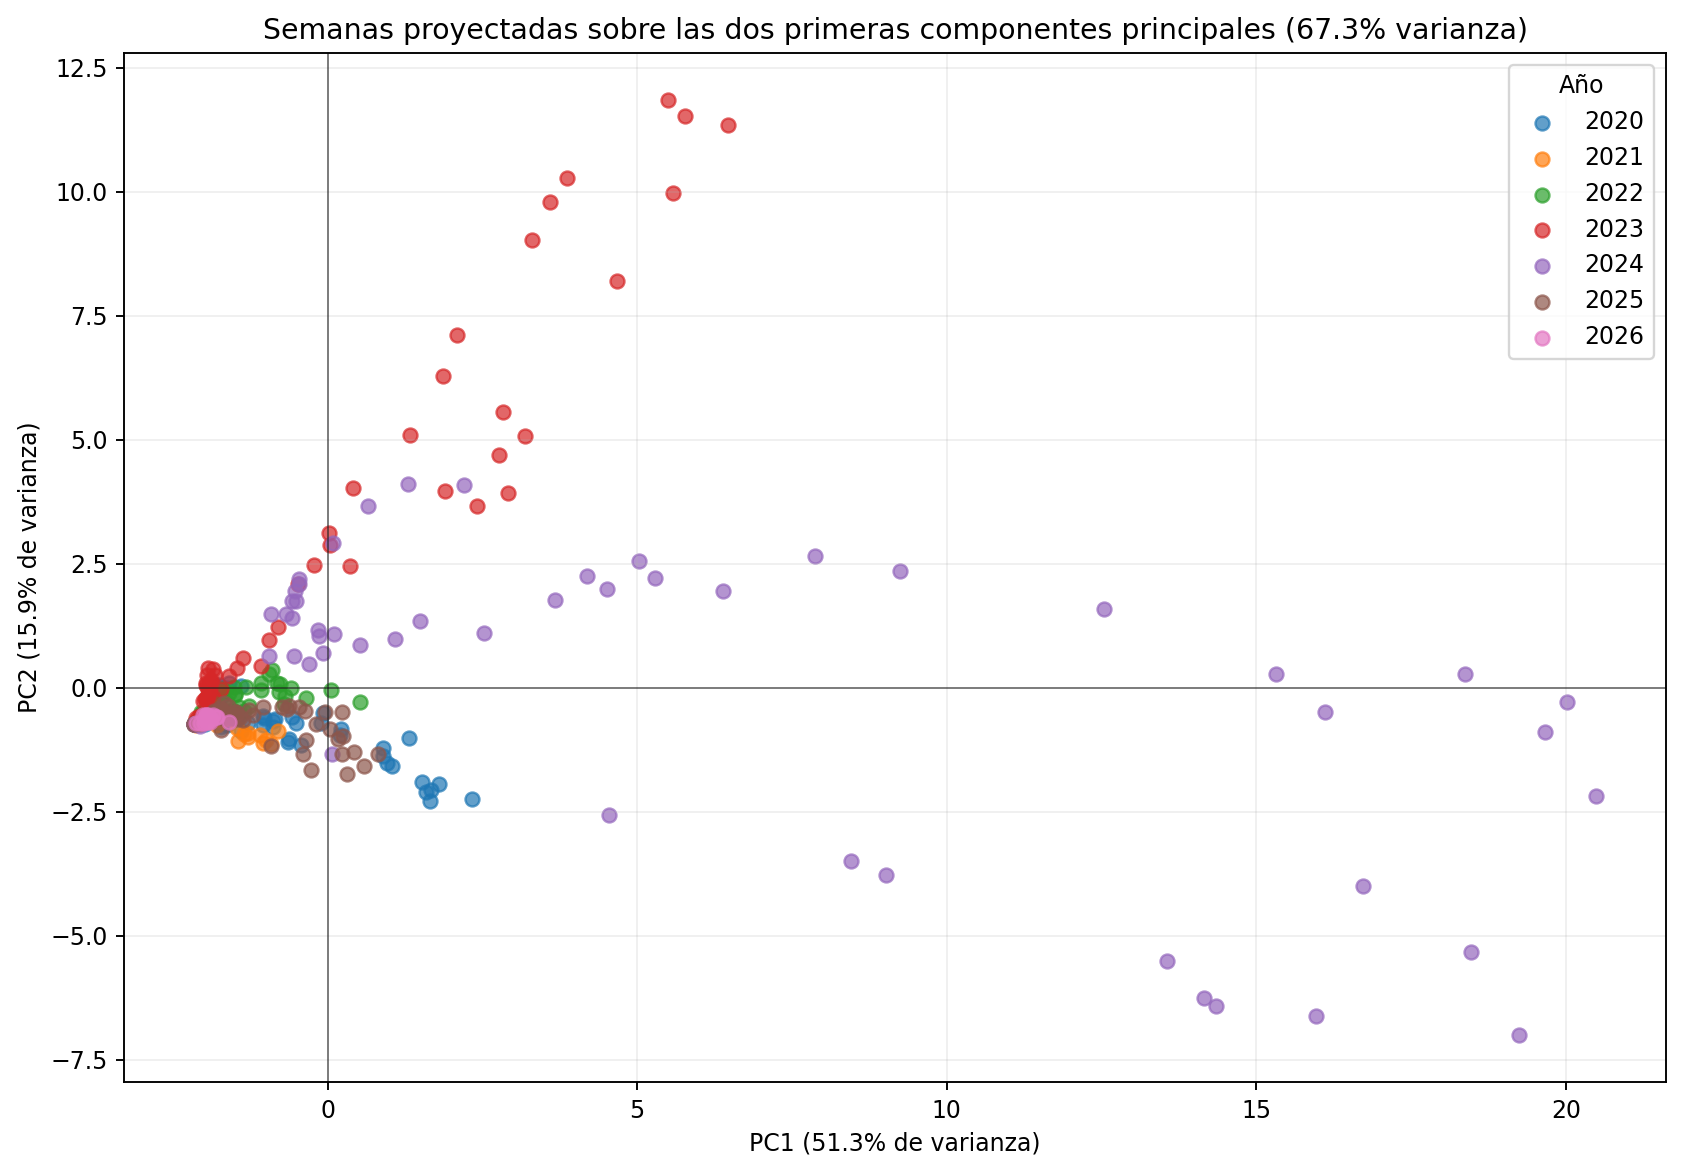

In [20]:
# PC1 vs PC2 
fig, ax = plt.subplots(figsize=(10, 7), dpi=170)

for anio in sorted(scores_df["anio"].unique()):

    datos_anio = scores_df[scores_df["anio"] == anio]

    ax.scatter(datos_anio["PC1"],datos_anio["PC2"],s=35,alpha=0.7,label=str(anio))

ax.axhline(0,linewidth=0.8,alpha=0.5, color="black")
ax.axvline(0,linewidth=0.8,alpha=0.5, color="black")
ax.set_title("Semanas proyectadas sobre las dos primeras componentes principales (67.3% varianza)")
ax.set_xlabel("PC1 (51.3% de varianza)")
ax.set_ylabel("PC2 (15.9% de varianza)")
ax.legend(title="Año")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Interpretación de los scores

Cada punto representa una semana del periodo estudiado.

Recordemos que $PC_1$ tiene pesos positivos para prácticamente todas las entidades.

Por ello, valores elevados de $PC_1$ indican semanas en las que muchas entidades presentan simultáneamente valores superiores a sus respectivos niveles habituales.

En la gráfica, varias semanas de 2024 aparecen muy desplazadas hacia la derecha, lo que sugiere episodios de elevada intensidad general.


El segundo componente presenta pesos positivos y negativos según la entidad.

Por ello, $PC_2$ representa principalmente un **contraste entre diferentes patrones estatales**.

Varias semanas de 2023 presentan valores excepcionalmente altos de $PC_2$, mientras que algunas semanas de 2024 alcanzan valores negativos importantes.

Esto indica que dos semanas pueden presentar niveles importantes de dengue pero diferir considerablemente en la manera en que los casos se distribuyen entre las entidades.

La representación mediante dos componentes conserva $67.23\%$ de la variabilidad original.

Por tanto, estamos representando 32 variables mediante únicamente dos coordenadas:

$$
(Z_1,\ldots,Z_{32})
\longrightarrow
(PC_1,PC_2),
$$

conservando una parte considerable de la estructura multivariada de los datos.

In [21]:
# Semanas extremas en PC1 y PC2

print("Semanas con valores más altos de PC1:")
display(scores_df[["FECHA", "anio", "PC1", "PC2"]]
    .sort_values("PC1",ascending=False)
    .head(10)
    .round(3))


print("\nSemanas con valores más altos de PC2:")
display(scores_df[["FECHA", "anio", "PC1", "PC2"]]
    .sort_values("PC2",ascending=False)
    .head(10)
    .round(3))


print("\nSemanas con valores más bajos de PC2:")
display(scores_df[["FECHA", "anio", "PC1", "PC2"]]
    .sort_values("PC2",ascending=True)
    .head(10)
    .round(3))

Semanas con valores más altos de PC1:


/var/folders/sb/mtj687d163q5v96jqt3zjjd00000gn/T/ipykernel_2496/1926793896.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3))


,FECHA,anio,PC1,PC2
246,2024-09-22,2024,20.487,-2.180
243,2024-09-01,2024,20.024,-0.285
244,2024-09-08,2024,19.658,-0.904
249,2024-10-13,2024,19.239,-7.010
248,2024-10-06,2024,18.462,-5.327
242,2024-08-25,2024,18.366,0.284
247,2024-09-29,2024,16.727,-3.997
245,2024-09-15,2024,16.117,-0.483
250,2024-10-20,2024,15.973,-6.617
241,2024-08-18,2024,15.320,0.275



Semanas con valores más altos de PC2:


/var/folders/sb/mtj687d163q5v96jqt3zjjd00000gn/T/ipykernel_2496/1926793896.py:14: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3))


,FECHA,anio,PC1,PC2
194,2023-09-24,2023,5.495,11.851
195,2023-10-01,2023,5.777,11.518
196,2023-10-08,2023,6.474,11.344
192,2023-09-10,2023,3.863,10.285
197,2023-10-15,2023,5.575,9.974
193,2023-09-17,2023,3.590,9.800
191,2023-09-03,2023,3.307,9.021
198,2023-10-22,2023,4.680,8.195
190,2023-08-27,2023,2.097,7.109
189,2023-08-20,2023,1.867,6.276



Semanas con valores más bajos de PC2:


/var/folders/sb/mtj687d163q5v96jqt3zjjd00000gn/T/ipykernel_2496/1926793896.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3))


,FECHA,anio,PC1,PC2
249,2024-10-13,2024,19.239,-7.010
250,2024-10-20,2024,15.973,-6.617
251,2024-10-27,2024,14.354,-6.413
252,2024-11-03,2024,14.164,-6.259
253,2024-11-10,2024,13.562,-5.519
248,2024-10-06,2024,18.462,-5.327
247,2024-09-29,2024,16.727,-3.997
254,2024-11-17,2024,9.015,-3.784
255,2024-11-24,2024,8.448,-3.497
256,2024-12-01,2024,4.544,-2.573


In [22]:
# Total semanal de casos
scores_df["casos_totales"] = datos[estados].sum(axis=1).values


# Correlación entre PC1 y el total semanal
corr_pc1_total = scores_df["PC1"].corr(scores_df["casos_totales"])

print("Correlación entre PC1 y "f"casos totales: {corr_pc1_total:.3f}")

Correlación entre PC1 y casos totales: 0.984


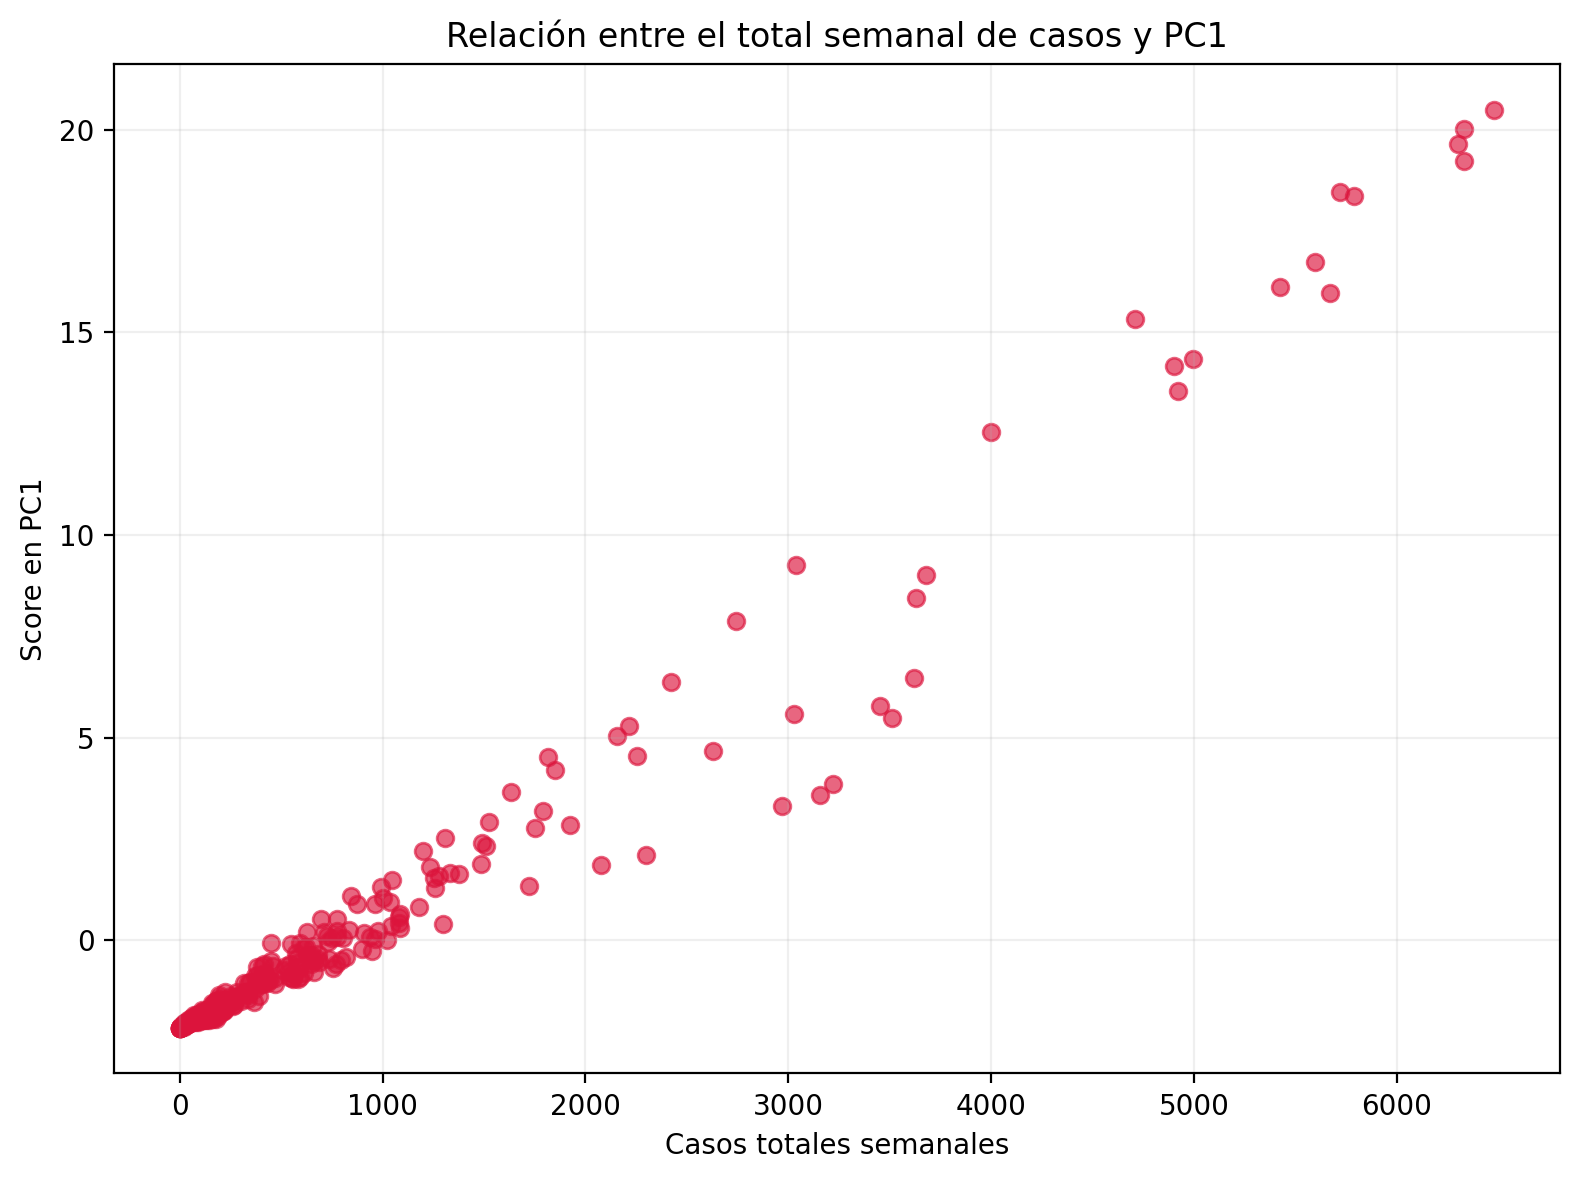

In [23]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=200)

ax.scatter(scores_df["casos_totales"],scores_df["PC1"],alpha=0.65, color='crimson')
ax.set_title("Relación entre el total semanal de casos y PC1")
ax.set_xlabel("Casos totales semanales")
ax.set_ylabel("Score en PC1")
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Relación entre PC1 y la intensidad general de dengue

El primer componente principal presenta una relación muy fuerte con el número total de casos registrados durante cada semana.

Recordemos que $PC_1$ se construye a partir de las variables estandarizadas:

$$
PC_1=a_1Z_1+a_2Z_2+\cdots+a_{32}Z_{32}.
$$

Como prácticamente todos sus coeficientes son positivos, cuando varias entidades presentan simultáneamente valores superiores a sus niveles habituales, el score de $PC_1$ aumenta.

La gráfica muestra que las semanas con mayor número total de casos también presentan valores elevados de $PC_1$.

Por tanto, podemos interpretar $PC_1$ como una medida de la **intensidad general del dengue entre las entidades**.

Sin embargo,

$$
PC_1
\neq
\text{total semanal de casos}.
$$

El total semanal utiliza los conteos originales, mientras que $PC_1$ utiliza la posición relativa de cada entidad respecto a su propia media y desviación estándar.

Por ello, $PC_1$ resume un patrón multivariado de actividad epidemiológica y no simplemente el número absoluto de casos.

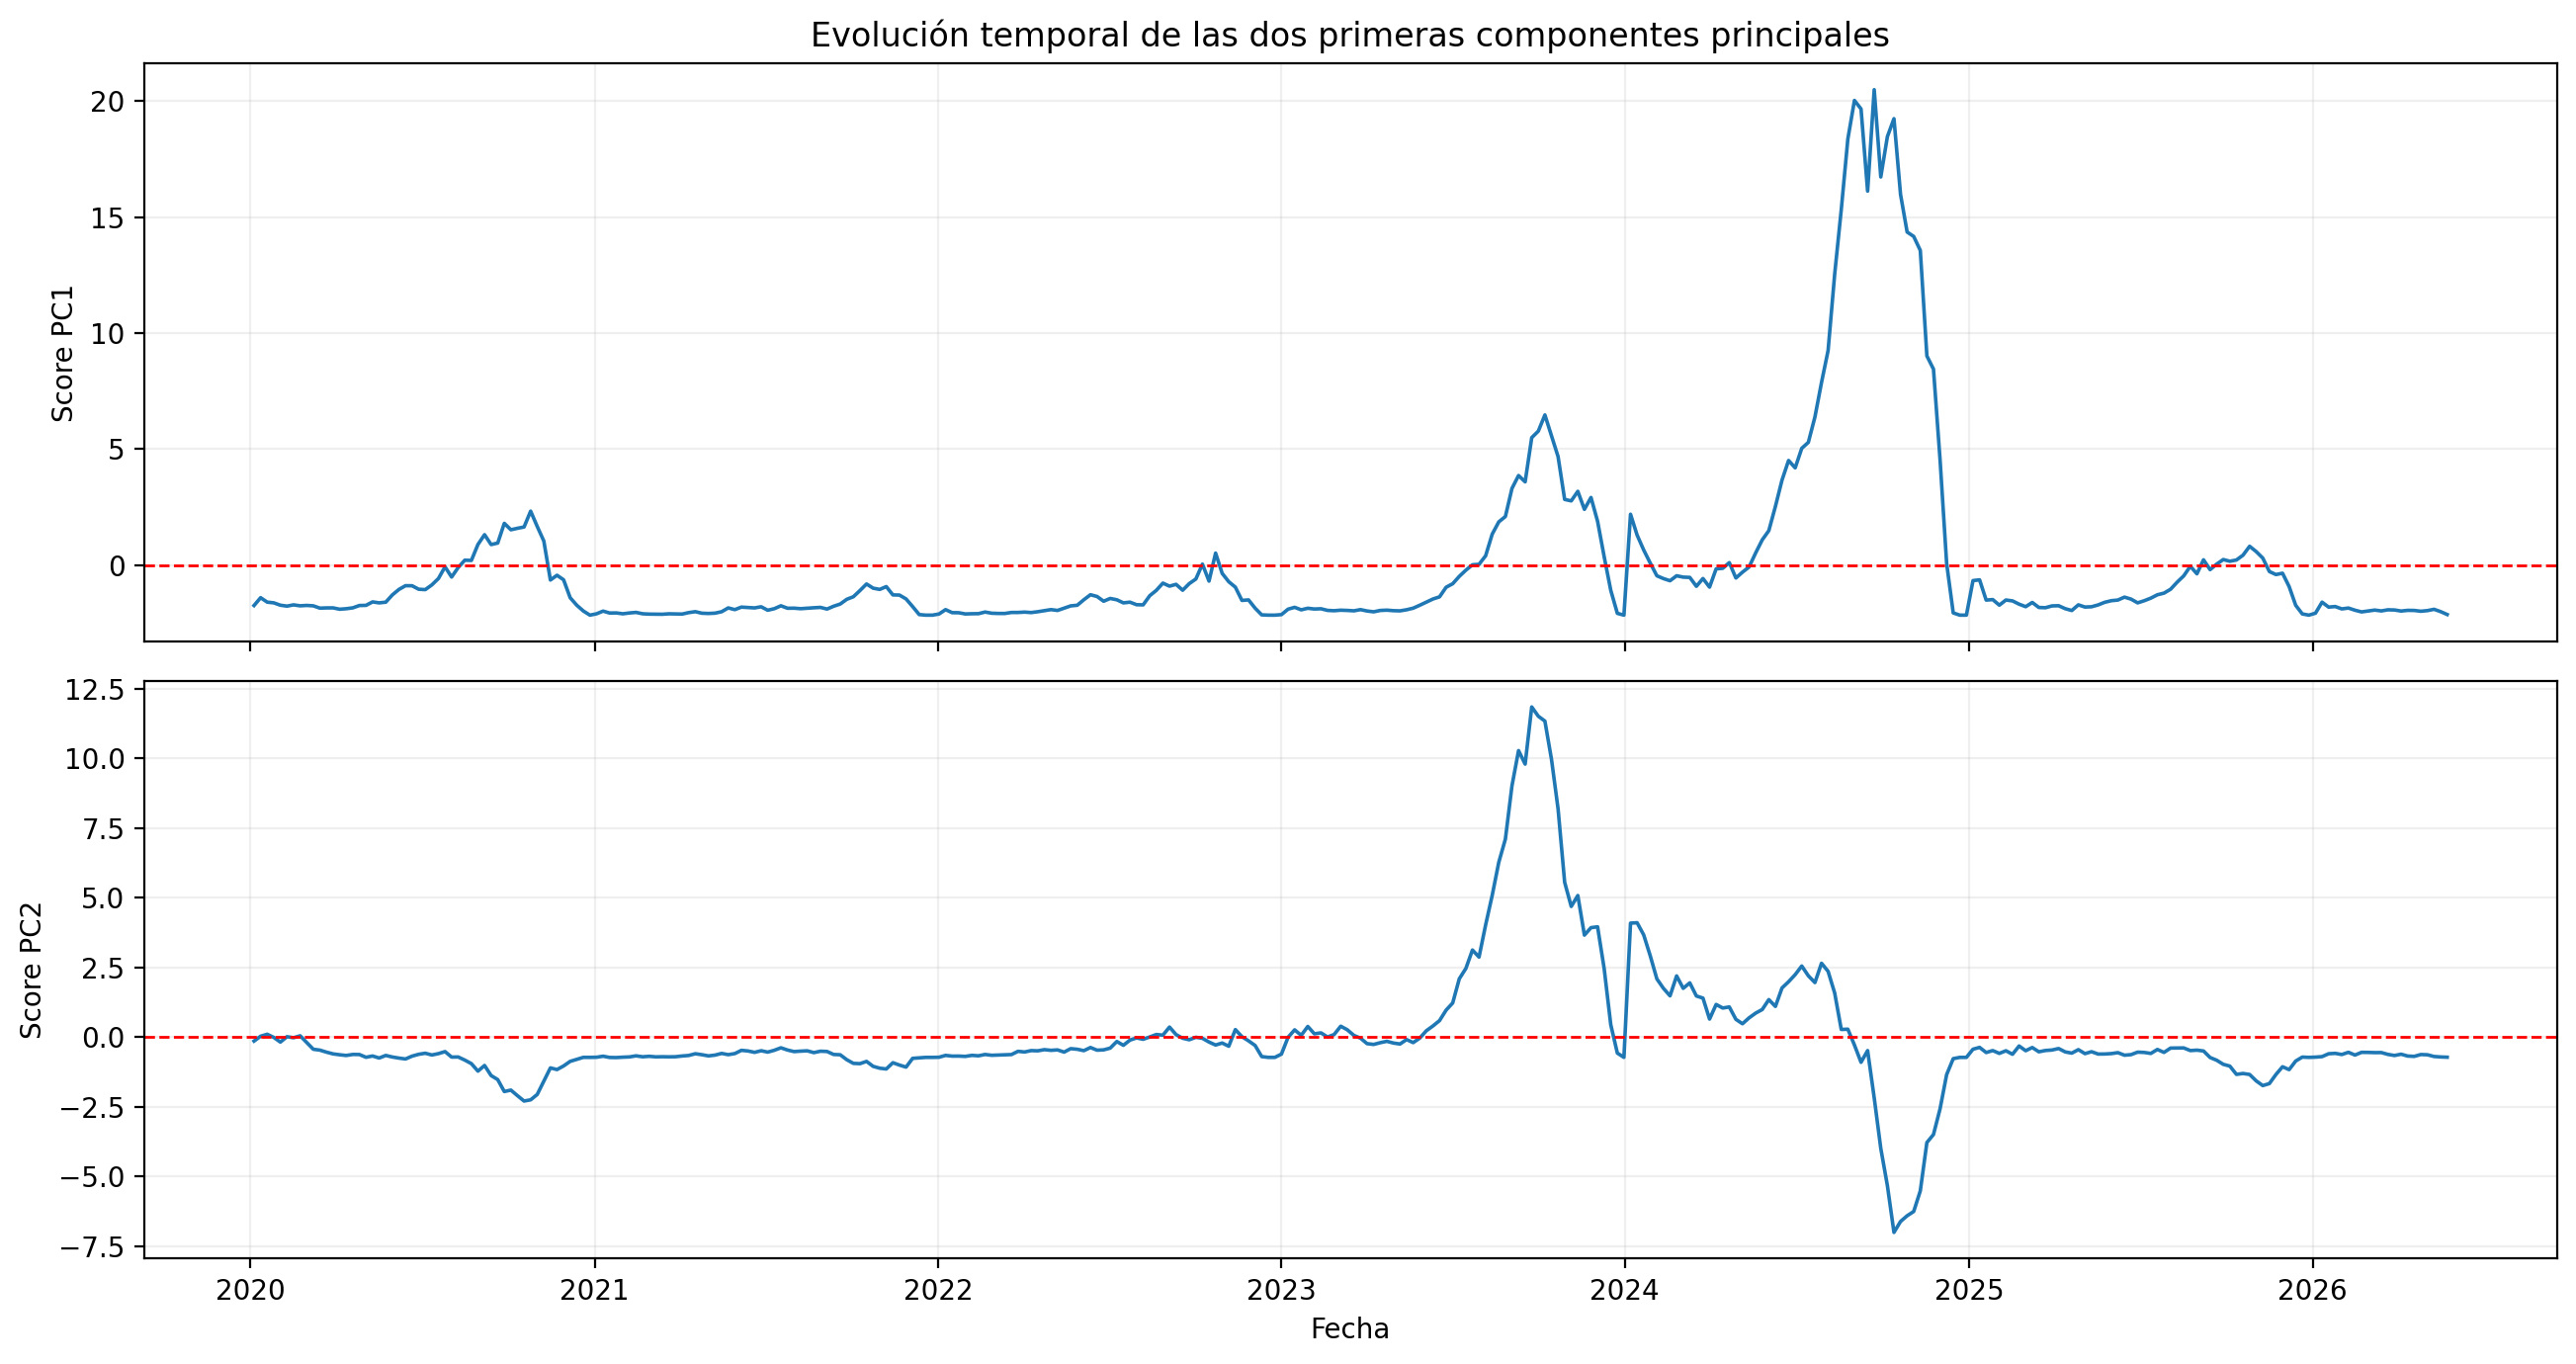

In [24]:
# Evolución temporal de PC1 y PC2
fig, axes = plt.subplots(2,1,figsize=(13, 7),sharex=True, dpi=200)

# PC1
axes[0].plot(scores_df["FECHA"],scores_df["PC1"],linewidth=1.3)
axes[0].axhline(0,linestyle="--",linewidth=1, color='red')
axes[0].set_ylabel("Score PC1")
axes[0].set_title("Evolución temporal de las dos primeras componentes principales")
axes[0].grid(alpha=0.2)

# PC2
axes[1].plot(scores_df["FECHA"],scores_df["PC2"],linewidth=1.3)
axes[1].axhline(0,linestyle="--",linewidth=1, color='red')
axes[1].set_ylabel("Score PC2")
axes[1].set_xlabel("Fecha")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Evolución temporal de las componentes principales

Las componentes principales también pueden analizarse como nuevas series temporales.

El primer componente, $PC_1$, presenta una relación extremadamente fuerte con el número total de casos semanales:

$$
\operatorname{Corr}
\left(
PC_1,\text{casos totales}
\right)
=
0.984.
$$

Esto respalda la interpretación de $PC_1$ como una medida sintética de la **intensidad general del dengue**.

En la serie temporal pueden identificarse distintos periodos de actividad, entre ellos un episodio particularmente intenso durante 2024.

Sin embargo, $PC_2$ muestra un comportamiento diferente.

Durante 2023 aparecen valores fuertemente positivos de $PC_2$, mientras que durante parte del episodio de 2024 se observan valores considerablemente negativos.

Esto muestra que dos periodos con actividad elevada pueden presentar estructuras diferentes entre las entidades.

En términos conceptuales:

$$
\boxed{
PC_1
\approx
\text{intensidad general}
}
$$

mientras que

$$
\boxed{
PC_2
\approx
\text{contraste entre patrones estatales}
}
$$

La segunda interpretación debe entenderse en términos de los pesos de $PC_2$: valores positivos y negativos representan diferentes configuraciones relativas entre las entidades.

Por tanto, PCA permite resumir simultáneamente:

- cuánto se aleja una semana del comportamiento habitual conjunto;
- y qué tipo de patrón multivariado caracteriza esa semana.

## Reconstrucción de los datos

PCA no solamente permite visualizar los datos en pocas dimensiones.

También permite construir una aproximación de las variables originales utilizando únicamente los primeros componentes.

Si conservamos $k$ componentes, obtenemos una aproximación

$$
X
\approx
\widehat X_k.
$$

Cuanto mayor sea $k$, mayor será la cantidad de información conservada.

En nuestros datos:

$$
k=2
\quad\Longrightarrow\quad
67.23\%
$$

de varianza explicada,

$$
k=5
\quad\Longrightarrow\quad
82.81\%,
$$

y

$$
k=8
\quad\Longrightarrow\quad
90.04\%.
$$

Compararemos el error de reconstrucción para estos tres casos.

## Error de reconstrucción: MAE y MSE

Cuando reducimos la dimensionalidad mediante PCA conservamos únicamente un número limitado de componentes principales.

A partir de estos componentes podemos reconstruir aproximadamente los datos originales:

$$
X
\approx
\widehat X.
$$

La diferencia entre el valor original y el valor reconstruido se denomina **error de reconstrucción**:

$$
e_{ij}
=
X_{ij}
-
\widehat X_{ij},
$$

donde:

- $X_{ij}$ es el valor original de la variable $j$ para la observación $i$;
- $\widehat X_{ij}$ es el valor reconstruido mediante PCA.

Para medir qué tan buena es la reconstrucción podemos utilizar el **MAE** y el **MSE**.



### Error absoluto medio: MAE

El **Mean Absolute Error** o error absoluto medio se define como

$$
MAE
=
\frac{1}{N}
\sum_{i,j}
\left|
X_{ij}
-
\widehat X_{ij}
\right|,
$$

donde $N$ representa el número total de valores comparados.

El MAE calcula, en promedio, cuánto difieren los valores reconstruidos de los valores originales.

Por ejemplo, si

$$
MAE=0.17,
$$

significa que, en promedio, la reconstrucción difiere aproximadamente $0.17$ unidades estandarizadas respecto al valor original.

Un valor pequeño de MAE indica una reconstrucción más cercana a los datos originales.



### Error cuadrático medio: MSE

El **Mean Squared Error** o error cuadrático medio se define como

$$
MSE
=
\frac{1}{N}
\sum_{i,j}
\left(
X_{ij}
-
\widehat X_{ij}
\right)^2.
$$

A diferencia del MAE, el MSE eleva los errores al cuadrado.

Por esta razón, las diferencias grandes reciben una penalización mayor.

Por ejemplo, un error de

$$
2
$$

contribuye al MSE con

$$
2^2=4,
$$

mientras que un error de

$$
0.5
$$

contribuye únicamente con

$$
0.5^2=0.25.
$$

Por ello, el MSE es especialmente sensible a reconstrucciones con errores grandes.

In [25]:
# Reconstrucción utilizando diferente número de componentes

resultados_reconstruccion = []
reconstrucciones = {}

for k in [2, 5, 8]:

    pca_k = PCA(n_components=k)

    # Proyección
    scores_k = pca_k.fit_transform(X_std)

    # Reconstrucción
    X_reconstruida = pca_k.inverse_transform(scores_k)

    reconstrucciones[k] = X_reconstruida

    # Error cuadrático medio
    mse = np.mean((X_std.to_numpy() - X_reconstruida) ** 2)

    # Error absoluto medio
    mae = np.mean(np.abs(X_std.to_numpy() - X_reconstruida))


    resultados_reconstruccion.append({
        "componentes": k,
        "varianza_explicada": (pca_k.explained_variance_ratio_.sum()),
        "MAE": mae,
        "MSE": mse
    })

resultados_reconstruccion = pd.DataFrame(resultados_reconstruccion)
resultados_reconstruccion.round(4)

,componentes,varianza_explicada,MAE,MSE
0,2,0.6723,0.2774,0.3277
1,5,0.8281,0.2131,0.1719
2,8,0.9004,0.1737,0.0996


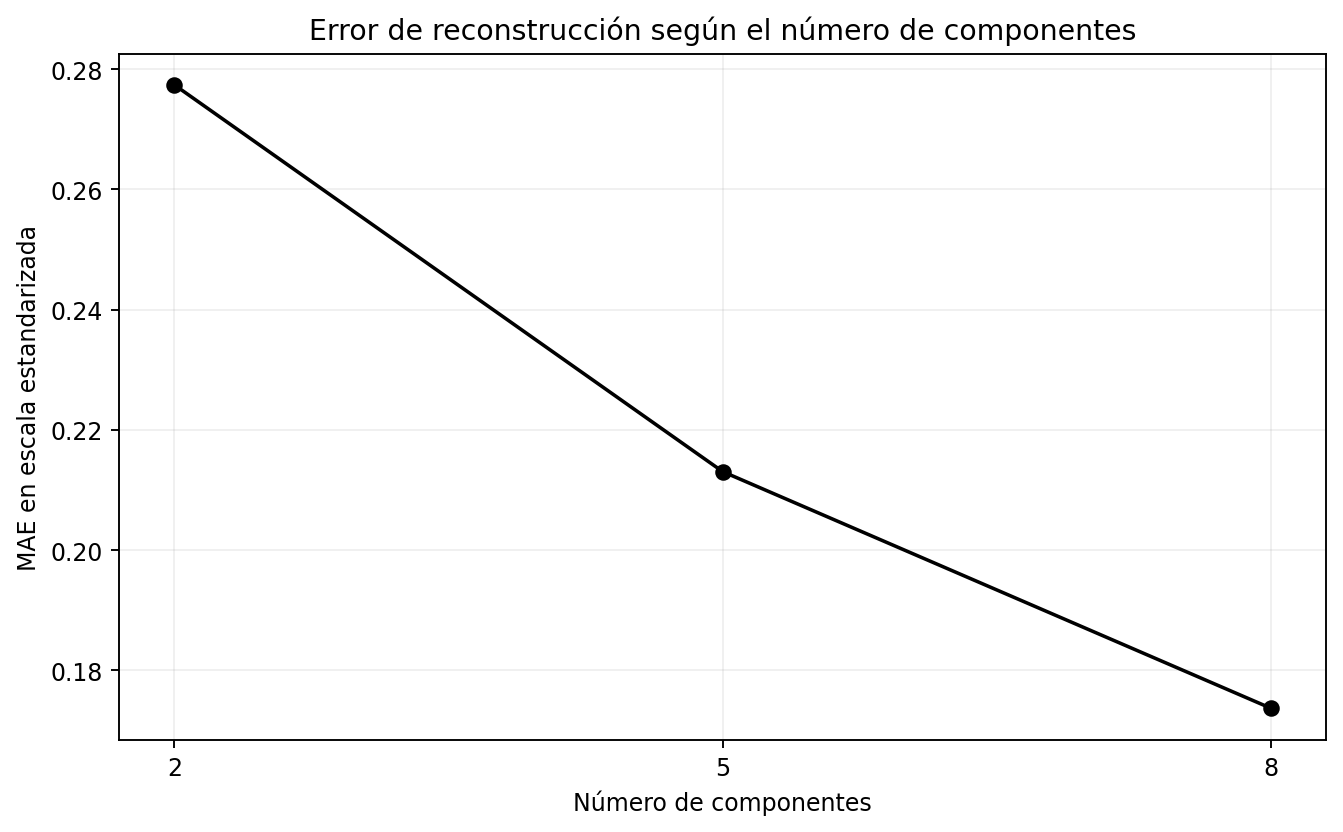

In [26]:
fig, ax = plt.subplots(figsize=(8, 5),dpi=170)

ax.plot(resultados_reconstruccion["componentes"],resultados_reconstruccion["MAE"],
    marker="o",linewidth=1.5,color='black')

ax.set_title("Error de reconstrucción según el número de componentes")
ax.set_xlabel("Número de componentes")
ax.set_ylabel("MAE en escala estandarizada")
ax.set_xticks([2, 5, 8])
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Compresión y pérdida de información

Al reducir el número de componentes principales aceptamos una pérdida de información.

Con $2$ componentes conservamos

$$
67.23\%
$$

de la varianza, mientras que con $8$ componentes conservamos

$$
90.04\%.
$$

Los errores de reconstrucción obtenidos fueron:

$$
\begin{array}{c|c|c|c}
k &
\text{Varianza explicada} &
\text{MAE} &
\text{MSE}\\
\hline
2 & 0.6723 & 0.2774 & 0.3277\\
5 & 0.8281 & 0.2131 & 0.1719\\
8 & 0.9004 & 0.1737 & 0.0996
\end{array}
$$

A medida que aumentamos el número de componentes:

$$
\boxed{
\text{más componentes}
\Rightarrow
\text{más información conservada}
\Rightarrow
\text{menor error de reconstrucción}
}
$$

En particular, debido a que PCA se aplicó sobre variables estandarizadas, observamos que

$$
\operatorname{MSE}_k
\approx
1-
\text{varianza explicada acumulada}.
$$

Por ejemplo, utilizando $8$ componentes:

$$
1-0.9004
=
0.0996,
$$

que coincide con el error cuadrático medio de reconstrucción.

Esto muestra claramente el compromiso fundamental de la reducción de dimensionalidad:

$$
\boxed{
\text{menor dimensión}
\quad\longleftrightarrow\quad
\text{mayor pérdida de información}
}
$$

En este caso, reducir de $32$ variables a $8$ componentes conserva aproximadamente el $90\%$ de la variabilidad original.

# Conclusiones

En este notebook utilizamos datos semanales de dengue para estudiar la estandarización y el Análisis de Componentes Principales.

## 1. Estandarización

Las entidades presentaban niveles de variabilidad muy diferentes.

La transformación

$$
Z_j=
\frac{X_j-\bar X_j}{s_j}
$$

permitió obtener variables con aproximadamente

$$
\bar Z_j=0,
\qquad
s_{Z_j}=1.
$$

Esto evita que las entidades con mayor varianza dominen automáticamente el análisis.



## 2. PCA

PCA transformó las $32$ variables originales en nuevas variables no correlacionadas denominadas componentes principales.

El primer componente explicó

$$
51.31\%
$$

de la variabilidad y los dos primeros componentes explicaron conjuntamente

$$
67.23\%.
$$

Para conservar aproximadamente el $90\%$ de la variabilidad fueron necesarios solamente

$$
8
$$

componentes.

Por tanto:

$$
\boxed{
32\text{ variables}
\longrightarrow
8\text{ componentes}
}
$$

con una pérdida relativamente pequeña de información.



## 3. Interpretación de las componentes

Los pesos de $PC_1$ fueron positivos para prácticamente todas las entidades.

Además,

$$
\operatorname{Corr}
\left(
PC_1,\text{casos totales semanales}
\right)
=
0.984.
$$

Por ello, $PC_1$ puede interpretarse como una medida sintética de la intensidad general del dengue.

En cambio, $PC_2$ presentó pesos positivos y negativos, por lo que representa principalmente contrastes entre diferentes patrones estatales.



## 4. Scores

Cada semana, que originalmente estaba representada mediante $32$ variables,

$$
(Z_1,\ldots,Z_{32}),
$$

puede proyectarse en un espacio de menor dimensión:

$$
(PC_1,PC_2,\ldots).
$$

La representación mediante $PC_1$ y $PC_2$ permitió identificar semanas y periodos con comportamientos multivariados diferentes.



## 5. Reconstrucción

La reducción dimensional implica una pérdida de información.

Con $8$ componentes conservamos aproximadamente

$$
90.04\%
$$

de la variabilidad y obtuvimos

$$
\operatorname{MSE}=0.0996.
$$

Por tanto, PCA proporciona un equilibrio entre:

$$
\boxed{
\text{simplificación}
+
\text{conservación de información}
}
$$